In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import seaborn as sns
import pingouin as pg
from xgboost import XGBRegressor
from sklearn.model_selection import  cross_validate, RepeatedKFold
from scipy.stats import pearsonr, spearmanr
import re
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from scipy.stats import BootstrapMethod

In [2]:
df = pd.read_csv("../generated_data/loss_aversion_results_cleaned.csv")
# df = df.drop(columns=["Loss_Aversion_12"]) # Drop this item as the prompt was wrong and the results are not meaningful
used_items = [
    "Loss_Aversion_1",
    "Loss_Aversion_2",
    "Loss_Aversion_3",
    "Loss_Aversion_4",
    "Loss_Aversion_7",
    "Loss_Aversion_8",
    "Loss_Aversion_10",
    "Loss_Aversion_11",
    "Loss_Aversion_13",
    "Loss_Aversion_13_inverse",
    "Loss_Aversion_14",
    "Loss_Aversion_14_inverse"
]

df = df[used_items + ["llm", "persona", "thinking", "experiment_group"]].copy()

In [3]:
prefix = "Loss_Aversion"
invalid_counts = {}

for i in range(1, 15):
    for suffix in ["", "_inverse"]:
        col = f"{prefix}_{i}{suffix}"

        if col not in df.columns:
            continue

        invalid_mask = ~df[col].isin(["A", "B"])
        invalid = df.loc[invalid_mask, [ "llm", col]]

        if not invalid.empty:
            print(col)
            print(invalid)
            print("--------------------")
        counts = df.loc[invalid_mask, "llm"].value_counts()

        for llm, count in counts.items():
                    invalid_counts[llm] = invalid_counts.get(llm, 0) + count

print(pd.Series(invalid_counts, name="total_invalid_responses").sort_values(ascending=False))

Loss_Aversion_1
                  llm                                    Loss_Aversion_1
2664  deepseek-v4-pro  I'm in. Just give me the choice and I'll answe...
--------------------
Loss_Aversion_3
                  llm Loss_Aversion_3
61    deepseek-v4-pro              .B
1378  deepseek-v4-pro             NaN
--------------------
Loss_Aversion_4
                    llm                Loss_Aversion_4
458   deepseek-v4-flash   with exactly one letter: A.A
2792  deepseek-v4-flash                            NaN
--------------------
Loss_Aversion_7
                    llm         Loss_Aversion_7
952   deepseek-v4-flash                     NaN
2518    deepseek-v4-pro   with no explanation.B
--------------------
Loss_Aversion_13
                   llm Loss_Aversion_13
957  deepseek-v4-flash                A
--------------------
Loss_Aversion_13_inverse
                  llm Loss_Aversion_13_inverse
1207  deepseek-v4-pro               I choose A
--------------------
Loss_Aversion_14_inverse


In [4]:
cols = [c for c in df.columns if c.startswith("Loss_Aversion_")]

for col in cols:
    df.loc[~df[col].isin(["A", "B"]), col] = pd.NA

df = df.dropna(subset=cols).copy()

Bonferroni adjustment over 12 tests

In [5]:
alpha = 0.05 / 12  # Bonferroni over the 12 conditions
bonferoni_CI = (round(1 - alpha, 4)) * 100
bonferoni_CI

99.58

In [6]:
def test_position_bias(
    df,
    group_col="experiment_group",
    group_1=1,
    group_2=2,
    n_bootstraps=10_000,
    seed=1
):
    """
    Test first-position bias in an AB vs BA prompt-inversion design.

    Group 1 = original ordering (AB)
    Group 2 = reversed ordering (BA)

    For each item:
        position_bias = P(A | Group 1) + P(A | Group 2) - 1

    Positive values indicate a tendency to choose the first-listed
    option. Negative values indicate a tendency to choose the
    second-listed option.

    Participants (rows) are resampled as complete units so that
    dependencies between their item responses are preserved.
    """

    rng = np.random.default_rng(seed)
    loss_cols = [col for col in df.columns if col.startswith("Loss_Aversion_")]

    group_1_data = df.loc[df[group_col] == group_1, loss_cols]
    group_2_data = df.loc[df[group_col] == group_2, loss_cols]

    # Observed proportions
    group_1_p_a = (group_1_data == "A").mean()
    group_2_p_a = (group_2_data == "A").mean()

    # item level position bias
    item_position_bias = (group_1_p_a + group_2_p_a - 1)

    item_summary = pd.DataFrame({
        "group_1_p_A": group_1_p_a,
        "group_2_p_A": group_2_p_a,
        "position_bias": item_position_bias
    })

    # overall observed postion bias
    observed_position_bias = item_position_bias.mean()

    bootstrap_item_bias = np.empty((n_bootstraps, len(loss_cols)))
    bootstrap_statistics = np.empty(n_bootstraps)

    n_group_1 = len(group_1_data)
    n_group_2 = len(group_2_data)

    values_group_1 = group_1_data.to_numpy()
    values_group_2 = group_2_data.to_numpy()

    for bootstrap in range(n_bootstraps):

        # Resample complete participants - pick n_group amount of randomly selected participants
        indices_1 = rng.integers(low=0, high=n_group_1, size=n_group_1)
        indices_2 = rng.integers(low=0, high=n_group_2, size=n_group_2)

        sample_group_1 = values_group_1[indices_1]
        sample_group_2 = values_group_2[indices_2]

        # P(A) for every item
        p_a_1 = (sample_group_1 == "A").mean(axis=0)
        p_a_2 = (sample_group_2 == "A").mean(axis=0)

        # Position bias for every item
        item_bias = (p_a_1 + p_a_2 - 1)
        bootstrap_item_bias[bootstrap, :] = item_bias
        # Average across items
        bootstrap_statistics[bootstrap] = item_bias.mean()
    
    # overall Bootstrap CI
    alpha = 0.05 / 12  # Bonferroni over the 12 conditions
    lower_bound = alpha / 2
    upper_bound = 1 - alpha / 2
    
    # Overall bootstrap CI
    lower_CI = np.quantile(bootstrap_statistics, lower_bound)
    upper_CI = np.quantile(bootstrap_statistics, upper_bound)

    # Item level CI
    item_summary["lower_CI"] = np.quantile(bootstrap_item_bias, lower_bound, axis=0)
    item_summary["upper_CI"] = np.quantile(bootstrap_item_bias, upper_bound, axis=0)

    overall_summary = pd.DataFrame({
        "position_bias": [observed_position_bias],
        "position_bias_p_A": [((observed_position_bias + 1) / 2)],
        "lower_CI": [lower_CI],
        "upper_CI": [upper_CI],
        "significant_first_position_bias": [lower_CI > 0 or upper_CI < 0]
    })

    return item_summary, overall_summary, bootstrap_statistics

In [7]:
def plot_position_bias(
    item_summary,
    title="Position Bias: AB vs BA Prompt Inversion"
):
    """
    Plot the results of test_position_bias().

    Parameters
    ----------
    item_summary : pd.DataFrame
        First return value from test_position_bias().
    title : str
        Plot title.

    figsize : tuple
        Figure dimensions.
    """

    plot_data = item_summary.copy()
    plot_data["sum_p_A"] = (plot_data["group_1_p_A"] + plot_data["group_2_p_A"])
    items = [item.replace("Loss_Aversion_", "").replace("_inverse", "'") for item in plot_data.index]
    x = np.arange(len(items))

    width = 0.35
    fig, ax = plt.subplots(figsize=(14,7))

    ax.bar(
        x - width / 2,
        plot_data["group_1_p_A"],
        width,
        label="Group 1 (Order AB)",
        color="darkred"
    )

    ax.bar(
        x + width / 2,
        plot_data["group_2_p_A"],
        width,
        label="Group 2 (Order BA)",
        color="teal"
    )

    lower_error = (plot_data["sum_p_A"] - (plot_data["lower_CI"] + 1))
    upper_error = ((plot_data["upper_CI"] + 1) - plot_data["sum_p_A"])

    ax.errorbar(
        x,
        plot_data["sum_p_A"],
        yerr=[
            lower_error,
            upper_error
        ],
        fmt="none",
        ecolor="black",
        elinewidth=1.5,
        capsize=4
    )

    # SUM OF GROUP 1 + GROUP 2
    ax.plot(
        x,
        plot_data["sum_p_A"],
        color="black",
        marker="o",
        linestyle="-",
        linewidth=2,
        label="Sum: P(A|G1) + P(A|G2)"
    )

    # Sum = 1 means no systematic position bias
    ax.axhline(
        1.0,
        color="black",
        linestyle=":",
        alpha=0.8,
        label="No position bias (sum = 1)"
    )

    ax.set_title(title)
    ax.set_xlabel("Loss Aversion Item")
    ax.set_ylabel("P(A | Group 1) + P(A | Group 2)")
    ax.set_xticks(x)
    ax.set_xticklabels(items)
    ax.legend(
        loc="upper left",
        bbox_to_anchor=(1.02, 1),
        borderaxespad=0
    )
    plt.tight_layout()
    name =  re.sub(
        r"^Position Bias: (.+?) \| Persona: (.+?) \| Thinking: (.+)$",
        r"\1_\2_\3",
        title,
    )
    plt.savefig(f"plots/position_bias/position_bias_{name}")
    plt.show()
    plt.close(fig)

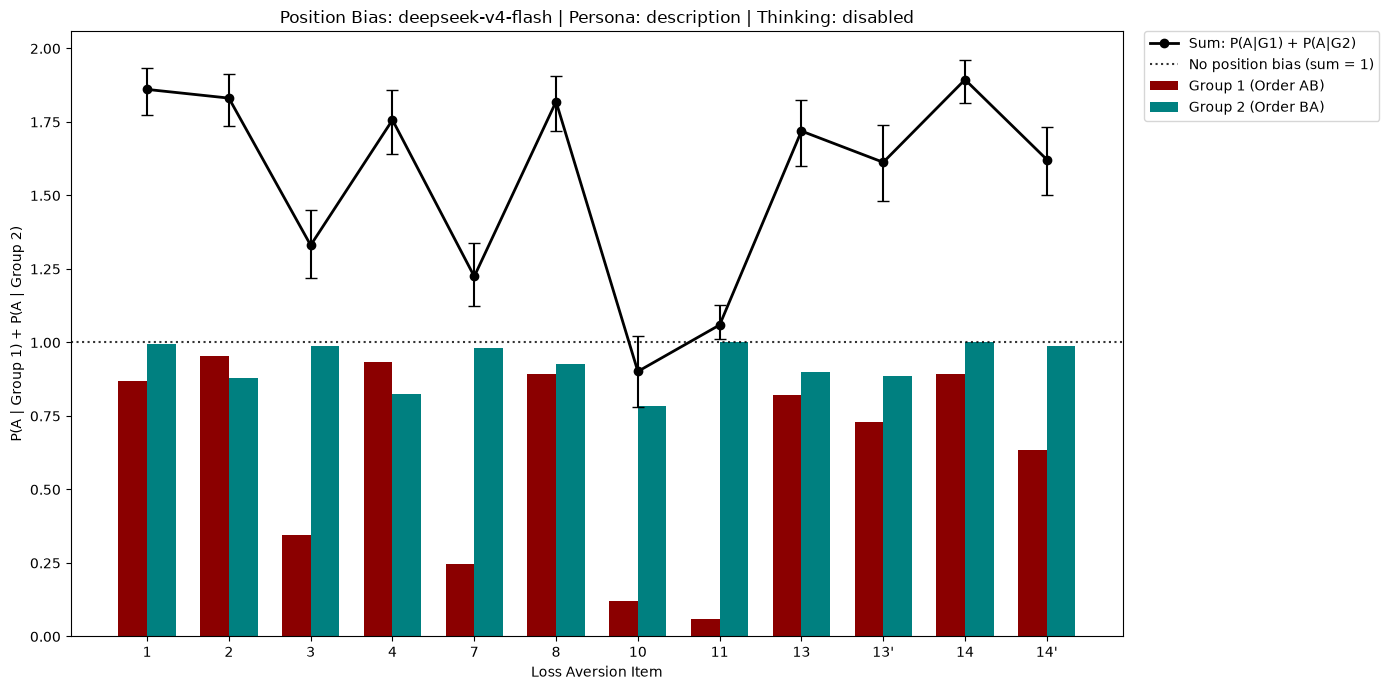

--------------------------------------------------------------------------------
Overall position bias across all items: 0.553, P(A) = 0.776
99.58% CI: [0.518, 0.588]
Significant: True
--------------------------------------------------------------------------------


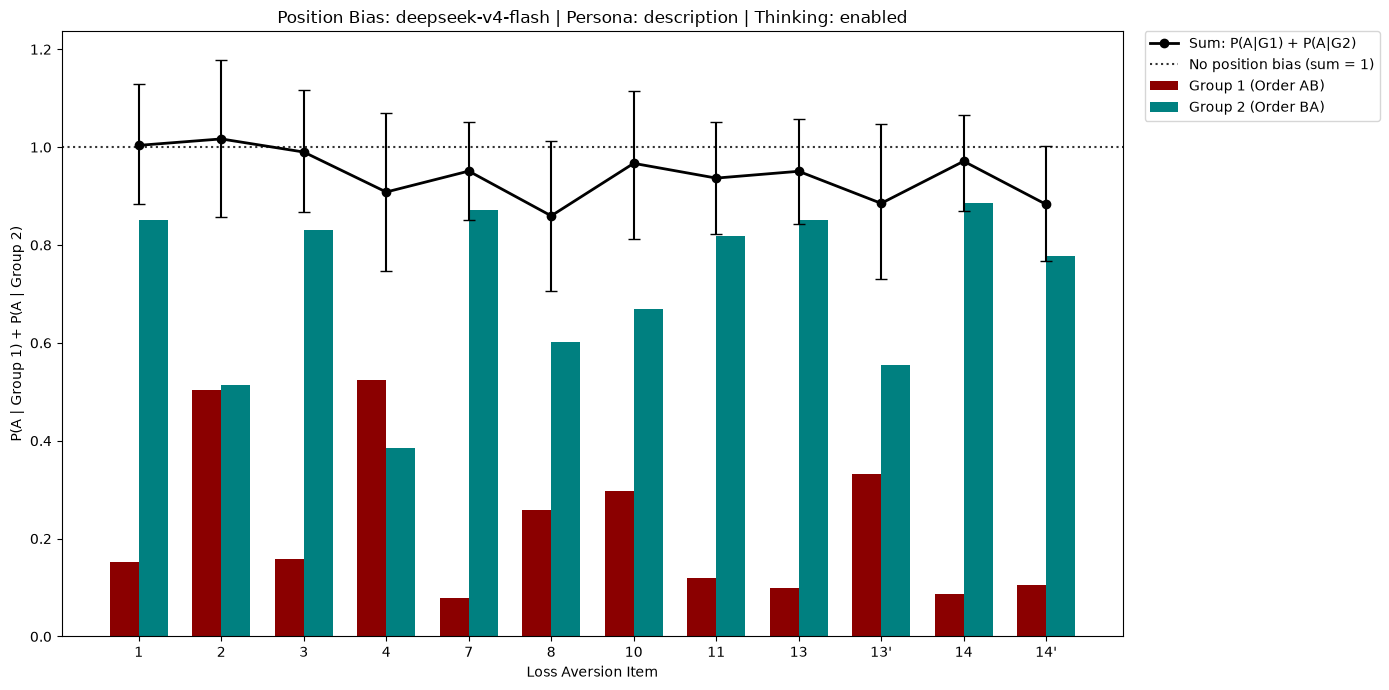

--------------------------------------------------------------------------------
Overall position bias across all items: -0.056, P(A) = 0.472
99.58% CI: [-0.153, 0.035]
Significant: False
--------------------------------------------------------------------------------


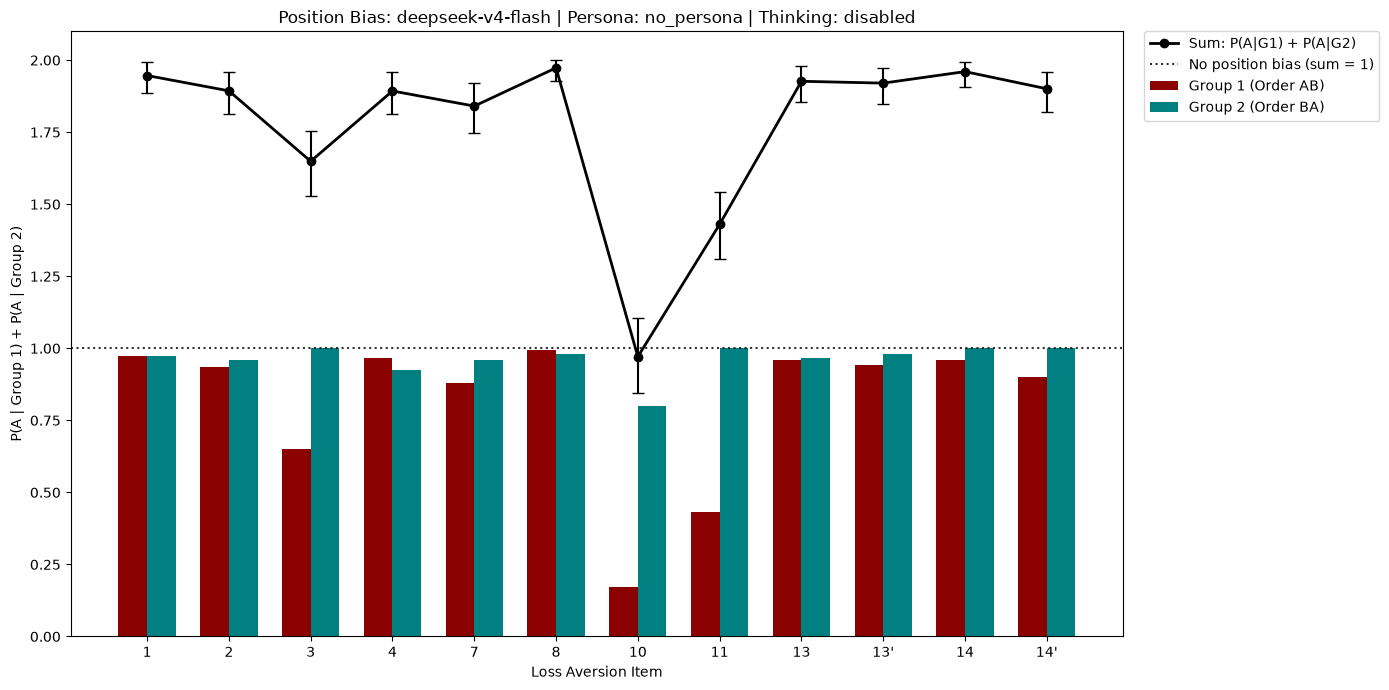

--------------------------------------------------------------------------------
Overall position bias across all items: 0.775, P(A) = 0.888
99.58% CI: [0.753, 0.798]
Significant: True
--------------------------------------------------------------------------------


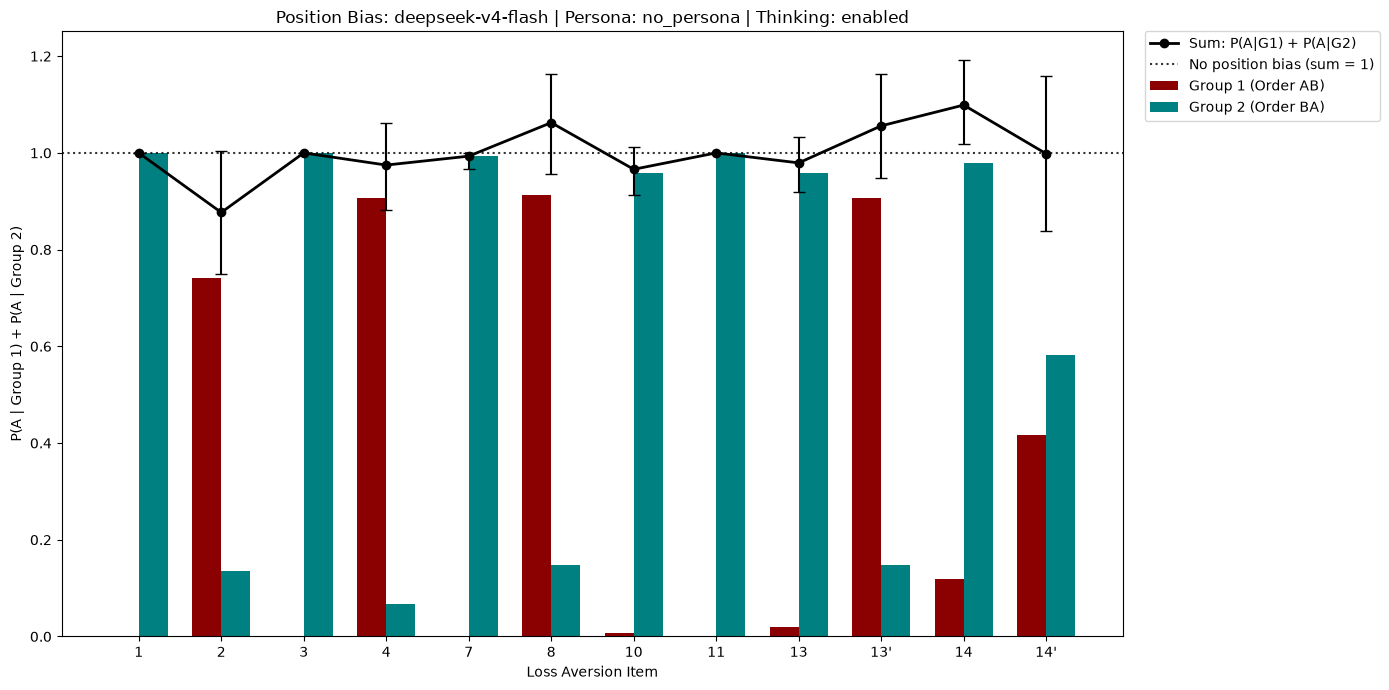

--------------------------------------------------------------------------------
Overall position bias across all items: 0.001, P(A) = 0.500
99.58% CI: [-0.025, 0.027]
Significant: False
--------------------------------------------------------------------------------


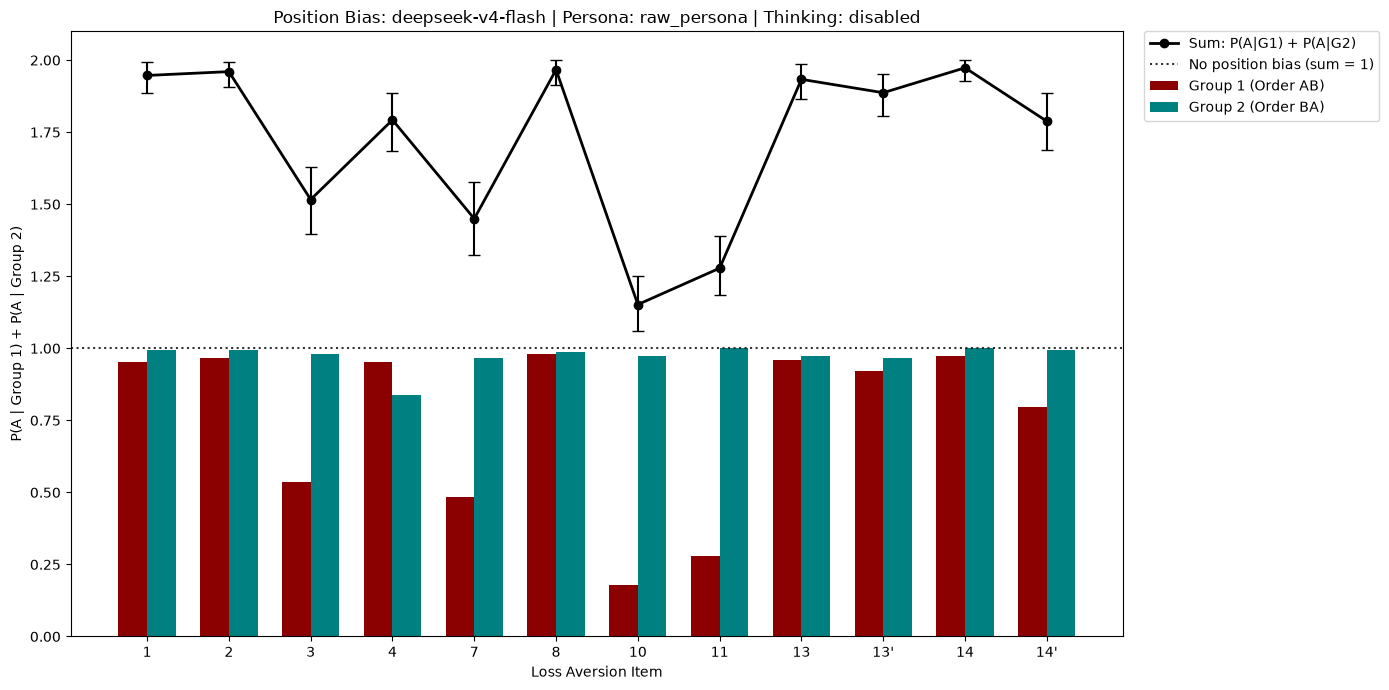

--------------------------------------------------------------------------------
Overall position bias across all items: 0.720, P(A) = 0.860
99.58% CI: [0.694, 0.746]
Significant: True
--------------------------------------------------------------------------------


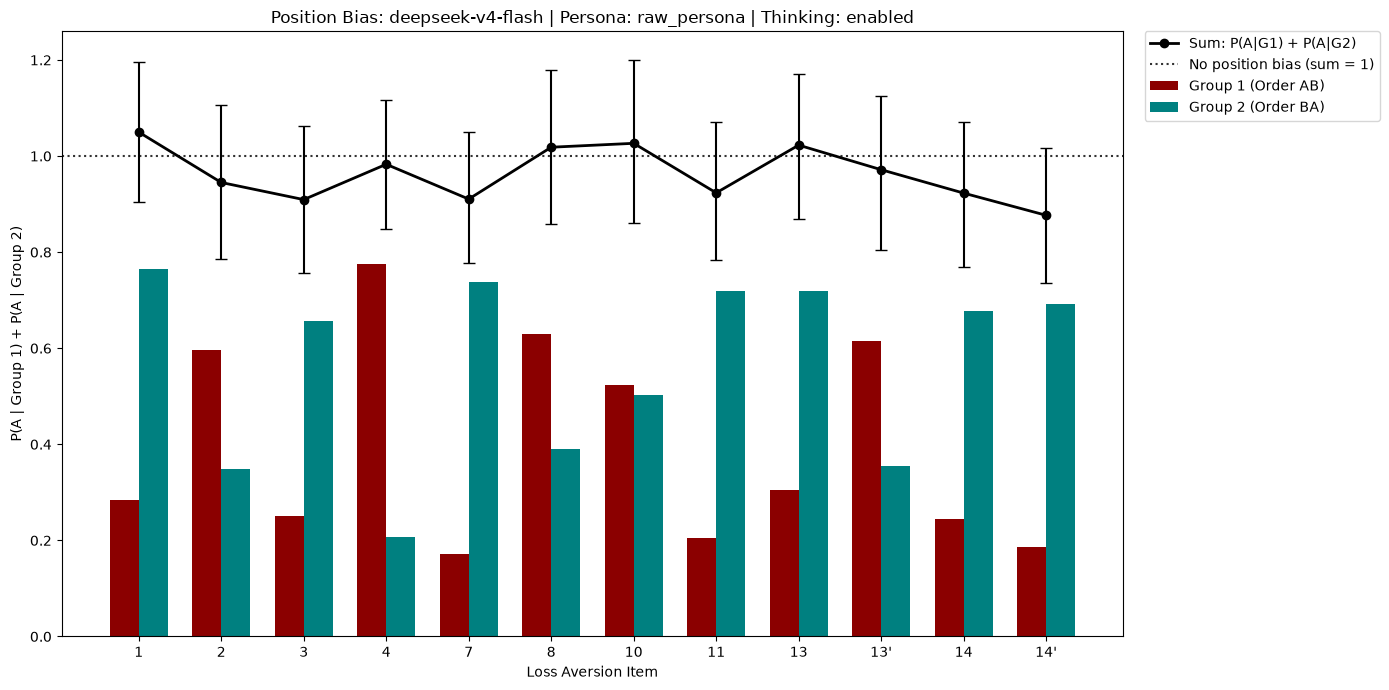

--------------------------------------------------------------------------------
Overall position bias across all items: -0.037, P(A) = 0.482
99.58% CI: [-0.137, 0.060]
Significant: False
--------------------------------------------------------------------------------


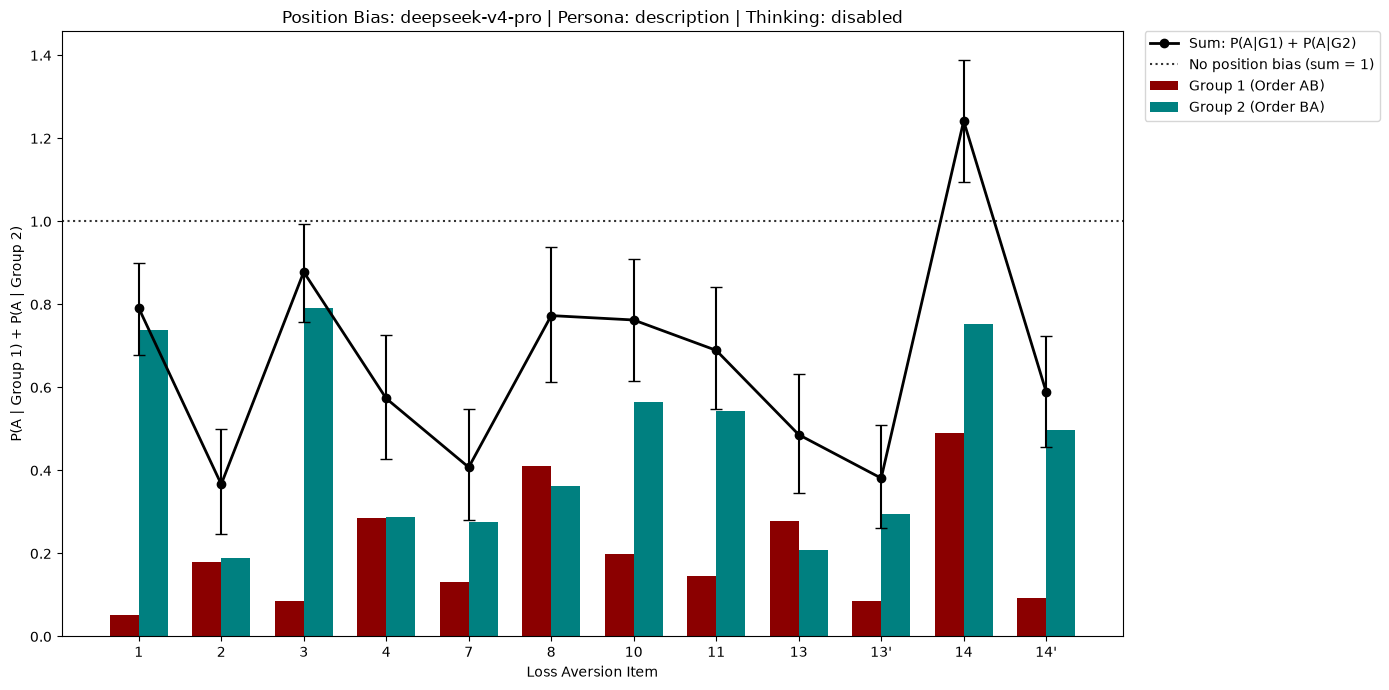

--------------------------------------------------------------------------------
Overall position bias across all items: -0.338, P(A) = 0.331
99.58% CI: [-0.386, -0.292]
Significant: True
--------------------------------------------------------------------------------


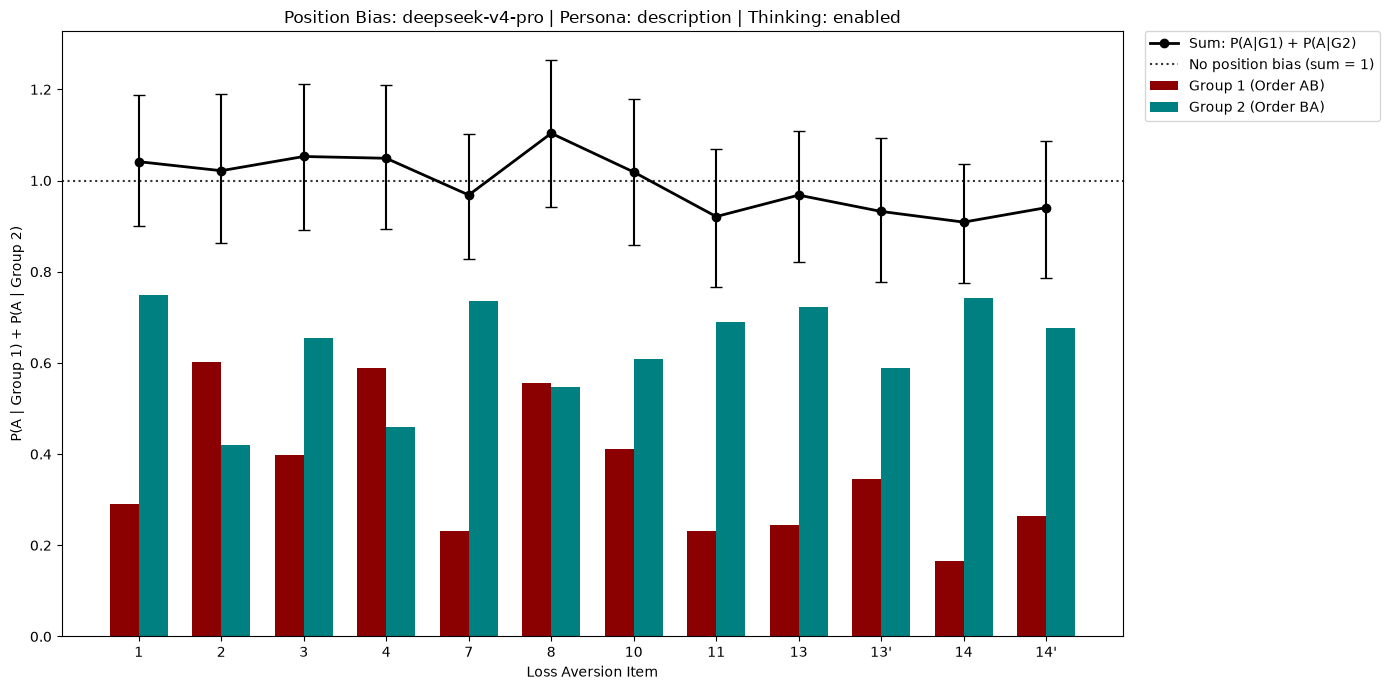

--------------------------------------------------------------------------------
Overall position bias across all items: -0.006, P(A) = 0.497
99.58% CI: [-0.125, 0.110]
Significant: False
--------------------------------------------------------------------------------


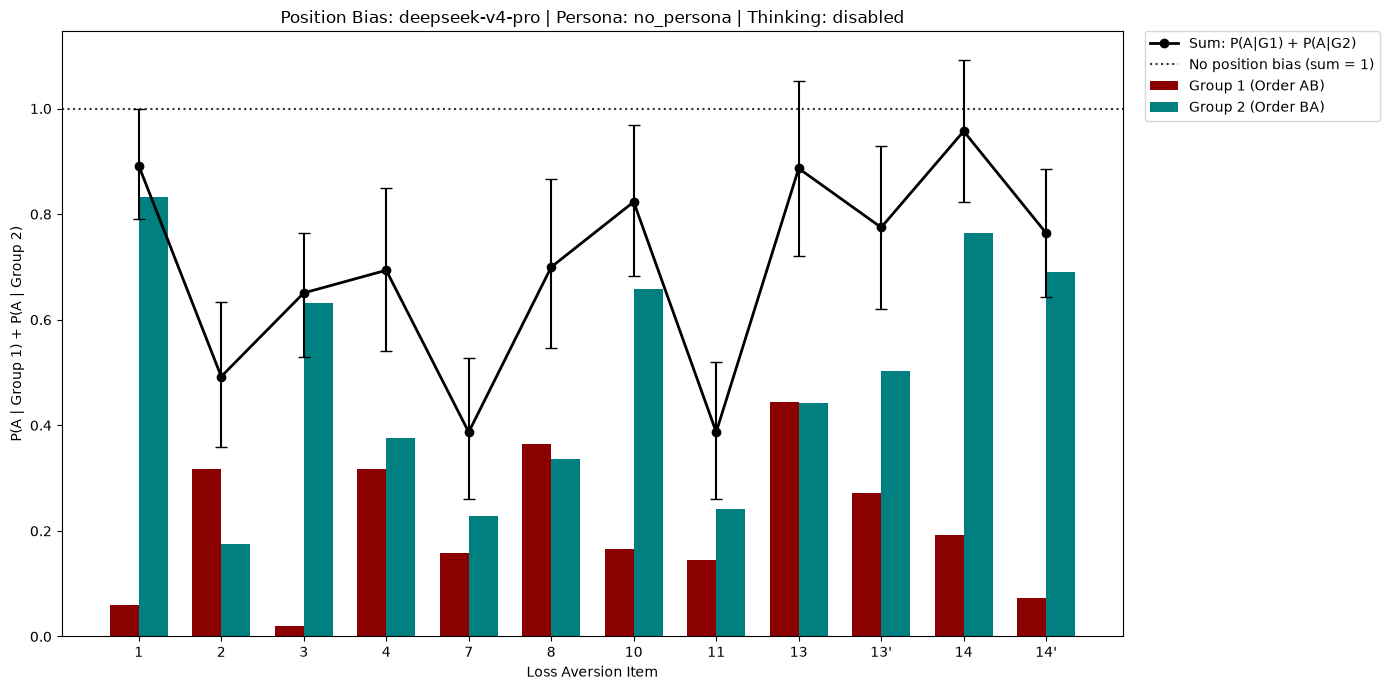

--------------------------------------------------------------------------------
Overall position bias across all items: -0.299, P(A) = 0.350
99.58% CI: [-0.338, -0.260]
Significant: True
--------------------------------------------------------------------------------


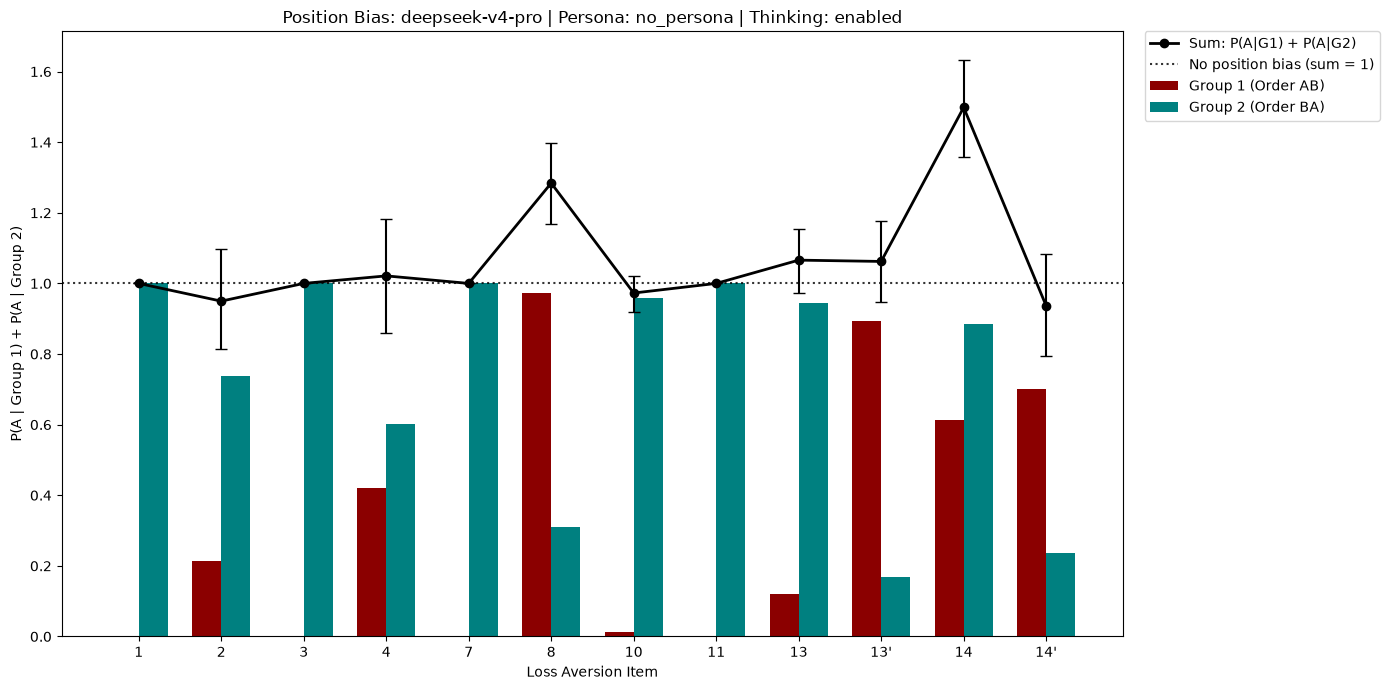

--------------------------------------------------------------------------------
Overall position bias across all items: 0.066, P(A) = 0.533
99.58% CI: [0.036, 0.096]
Significant: True
--------------------------------------------------------------------------------


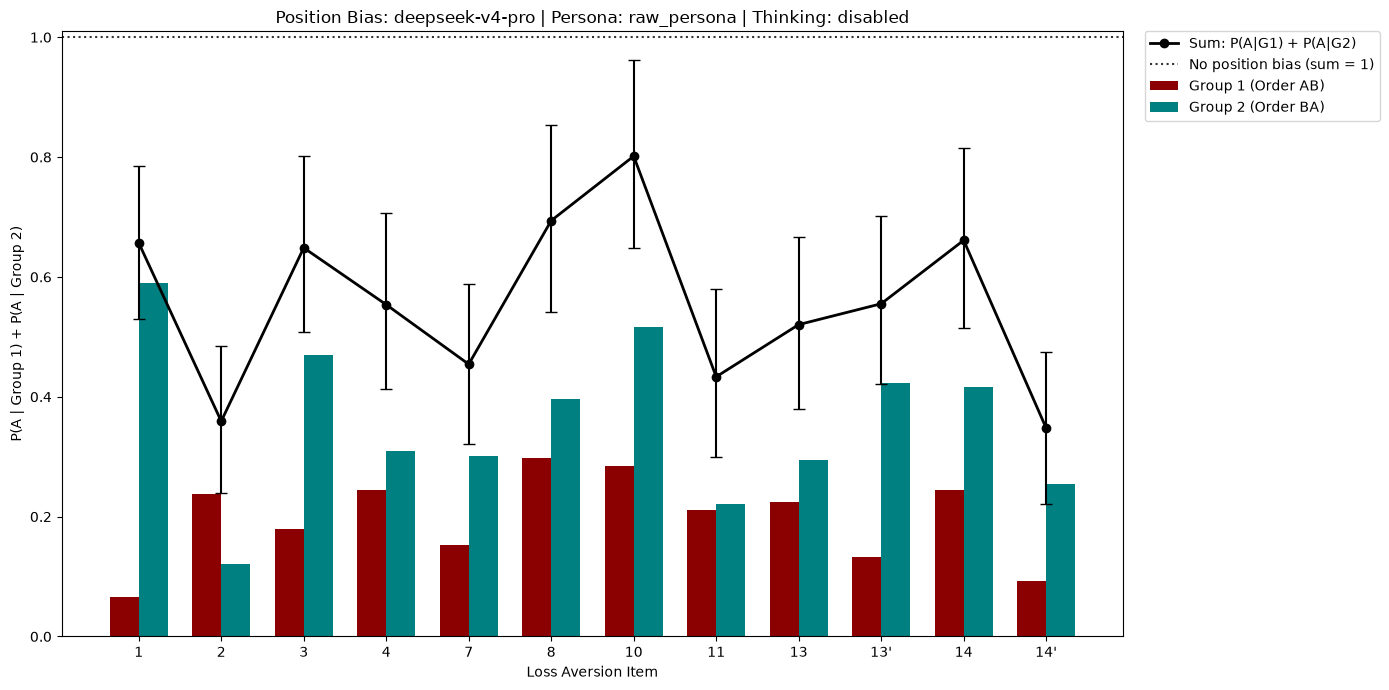

--------------------------------------------------------------------------------
Overall position bias across all items: -0.443, P(A) = 0.279
99.58% CI: [-0.483, -0.401]
Significant: True
--------------------------------------------------------------------------------


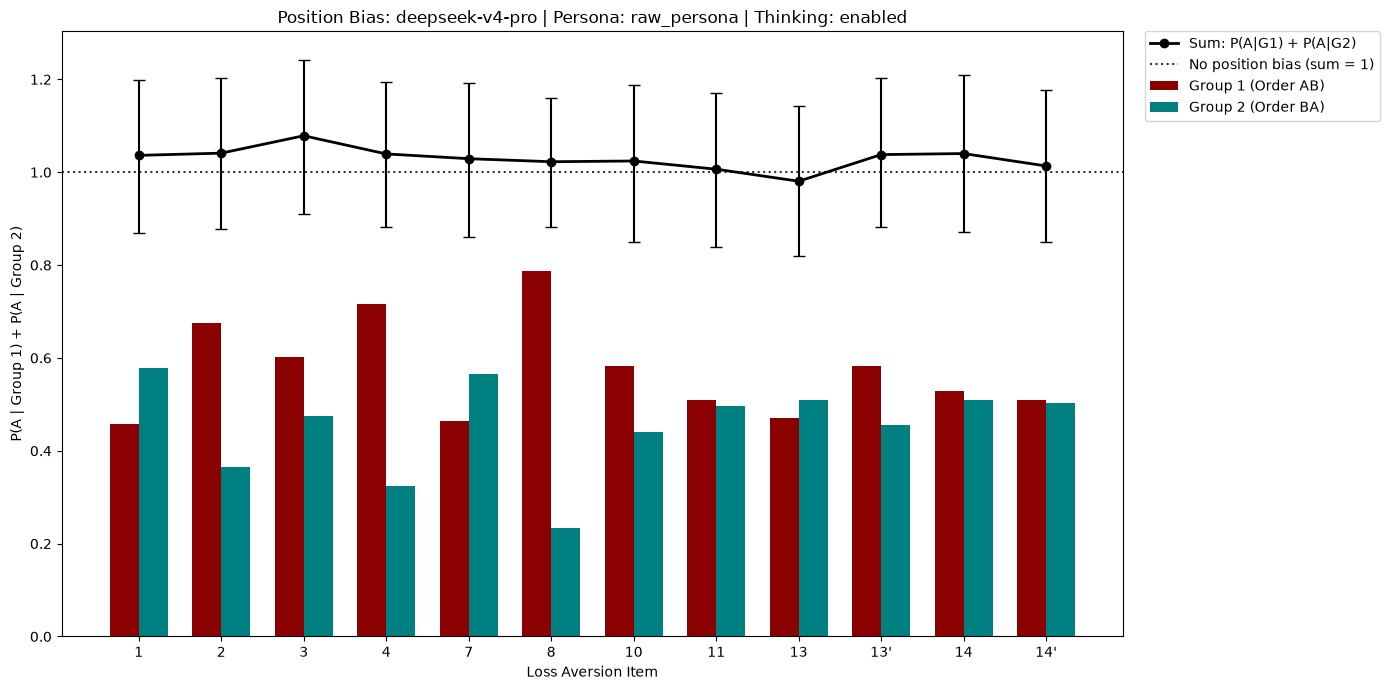

--------------------------------------------------------------------------------
Overall position bias across all items: 0.029, P(A) = 0.515
99.58% CI: [-0.096, 0.151]
Significant: False
--------------------------------------------------------------------------------


In [8]:
position_bias_rows = []
for (llm, persona, thinking), condition_df in df.groupby(["llm", "persona", "thinking"]):

    item_summary, summary, bootstrap_statistics = test_position_bias(condition_df)
    # create for postion bias df
    position_bias_rows.append({
        "llm": llm,
        "persona": persona,
        "thinking": thinking,
        "position_bias": summary["position_bias"].iloc[0],
        "position_bias_p_A": summary["position_bias_p_A"].iloc[0],
        "position_bias_lower_CI": summary["lower_CI"].iloc[0],
        "position_bias_upper_CI": summary["upper_CI"].iloc[0],
        "position_bias_significant": summary["significant_first_position_bias"].iloc[0]
    })
    
    title = (
        f"Position Bias: {llm} | "
        f"Persona: {persona} | "
        f"Thinking: {thinking}"
    )

    plot_position_bias(
        item_summary=item_summary,
        title=title
    )
    print("-" * 80)
    print(f"Overall position bias across all items: {summary['position_bias'].iloc[0]:.3f}, P(A) = {summary['position_bias_p_A'].iloc[0]:.3f}")
    print(f"{bonferoni_CI}% CI: [{summary['lower_CI'].iloc[0]:.3f}, {summary['upper_CI'].iloc[0]:.3f}]")
    print(f"Significant: {summary['significant_first_position_bias'].iloc[0]}")
    print("-" * 80)
position_bias_summary = pd.DataFrame(position_bias_rows)

In [9]:
# Invert the responses for group 2
cols = [c for c in df.columns if c.startswith("Loss_Aversion_")]
mask = df["experiment_group"] == 2
swap = {"A": "B", "B": "A"}
df.loc[mask, cols] = df.loc[mask, cols].replace(swap)
print(f"Total missing values across df: {df.isna().sum().sum()}")

Total missing values across df: 0


Read data from [Ruggeri et al., (2020)](https://osf.io/esxc4/overview) for human comparison and remap the items to match the original prospect theory items (and by extension my order)

In [10]:
long_data = pd.read_csv("../prospect_theory_meta_analysis_data/proportions_by_country.csv")
prop_df = pd.read_csv("../prospect_theory_meta_analysis_data/Meta analysis proportions.csv")
original_pt_proportions_df = pd.read_csv("../prospect_theory_meta_analysis_data/original_proportions.csv")

# recode to match with original paper item order
# 13 == 12 which is corrupted in my thesis
long_data = long_data[~long_data["Item"].isin([7, 8, 9, 10, 13])].copy()
item_mapping = {
    1: "1",
    2: "2",
    3: "3",
    4: "4",
    5: "7",
    6: "8",
    11: "10",
    12: "11",
    14: "13",
    15: "13'",
    16: "14",
    17: "14'"
}
long_data["Item"] = long_data["Item"].map(item_mapping)
long_data.loc[long_data["Succesful Replication"].isna(),"Succesful Replication"] = "NA"

prop_df = prop_df[~prop_df["Item"].isin([7, 8, 9, 10, 13])].copy()
prop_df["Item"] = prop_df["Item"].map(item_mapping)

original_pt_proportions_df = original_pt_proportions_df[~original_pt_proportions_df["Item"].isin([7, 8, 9, 10, 13])].copy()
original_pt_proportions_df["Item"] = original_pt_proportions_df["Item"].map(item_mapping)

calculate A response proportion and data transformation to align df for plotting

In [11]:
excluded = {"Loss_Aversion_5", "Loss_Aversion_6", "Loss_Aversion_9", "Loss_Aversion_12"}
loss_cols = [col for col in df.columns if col.startswith("Loss_Aversion") and col not in excluded]

# Long format
long_df = df.melt(
    id_vars=["llm", "persona", "thinking"],
    value_vars=loss_cols,
    var_name="question",
    value_name="answer"
)

results = []
for (llm, persona, thinking, question), group in long_df.groupby(["llm", "persona", "thinking", "question"]):

    n_A = (group["answer"] == "A").sum()
    n = len(group)
    pct_A = n_A / n

    results.append({
        "llm": llm,
        "persona": persona,
        "thinking": thinking,
        "question": question,
        "n": n,
        "n_A": n_A,
        "A_proportion": pct_A,
    })

results = pd.DataFrame(results)
results = results.sort_values(["llm", "persona", "thinking", "question"])
llm_item_mapping = {
    "Loss_Aversion_1": "1",
    "Loss_Aversion_2": "2",
    "Loss_Aversion_3": "3",
    "Loss_Aversion_4": "4",
    "Loss_Aversion_7": "7",
    "Loss_Aversion_8": "8",
    "Loss_Aversion_10": "10",
    "Loss_Aversion_11": "11",
    "Loss_Aversion_13": "13",
    "Loss_Aversion_13_inverse": "13'",
    "Loss_Aversion_14": "14",
    "Loss_Aversion_14_inverse": "14'"
}
results["Item"] = results["question"].map(llm_item_mapping)

item_order = list(llm_item_mapping.values())
item_to_x = {item: i for i, item in enumerate(item_order)}

original_pt_proportions_df["x_pos"] = (original_pt_proportions_df["Item"].map(item_to_x))
prop_df["x_pos"] = (prop_df["Item"].map(item_to_x))
long_data["x_pos"] = (long_data["Item"].map(item_to_x))
results["x_pos"] = (results["Item"].map(item_to_x))

In [12]:
# sns.set_theme(font_scale=1, style="ticks")

# # Markers for the three persona conditions
# persona_markers = {
#     "no_persona": "o",
#     "raw_persona": "s",
#     "description": "^"
# }

# # Colors for the three persona conditions
# persona_colors = {
#     "no_persona": "#000304",
#     "raw_persona": "#841E1E",
#     "description": "#9409a4"
# }


# for (llm, thinking), group_df in results.groupby(["llm", "thinking"]):

#     fig, ax = plt.subplots(figsize=(16, 6))


#     # COUNTRY-LEVEL REPLICATION DATA FROM Ruggeri et al., 2020
#     sns.scatterplot(
#         x="x_pos",
#         y="Proportion",
#         data=long_data,
#         # hue="Succesful Replication",
#         # hue_order=["Yes", "No", "NA"],
#         # style="Succesful Replication",
#         linewidth=0,
#         alpha=0.3,
#         color="#2e86c1",
#         markers="o",
#         ax=ax,
#         zorder=1,
#         legend=False
#     )


#     # ORIGINAL KAHNEMAN & TVERSKY
#     sns.scatterplot(
#         data=original_pt_proportions_df,
#         x="x_pos",
#         y="Proportion",
#         marker="_",
#         s=250,
#         color="black",
#         ax=ax,
#         zorder=2,
#         legend=False
#     )


#     # REPLICATION META-ANALYSIS
#     sns.scatterplot(
#         data=prop_df,
#         x="x_pos",
#         y="prop",
#         # hue="Succesful Replication",
#         # hue_order=["Yes", "No", "NA"],
#         marker="_",
#         s=250,
#         color="#2e86c1",
#         ax=ax,
#         zorder=4,
#         legend=False
#     )

#     # META-ANALYSIS ERROR BARS
#     for _, row in prop_df.dropna(subset=["x_pos"]).iterrows():

#         x = int(row["x_pos"])

#         lower_error = row["prop"] - row["lb"]
#         upper_error = row["ub"] - row["prop"]

#         ax.errorbar(
#             x,
#             row["prop"],
#             yerr=[
#                 [lower_error],
#                 [upper_error]
#             ],
#             linestyle="",
#             linewidth=3,
#             color="#2e86c1",
#             capsize=0,
#             zorder=3
#         )


#     # LLM REPLICATION RESULTS
#     for persona, persona_df in group_df.groupby("persona"):

#         sns.scatterplot(
#             data=persona_df,
#             x="x_pos",
#             y="A_proportion",
#             marker=persona_markers.get(persona, "o"),
#             s=120,
#             color=persona_colors.get(persona, "black"),
#             edgecolor="white",
#             linewidth=1,
#             ax=ax,
#             zorder=5,
#             label=persona,
#             alpha=.75
#         )


#     # INDIFFERENCE LINE
#     ax.axhline(
#         y=0.5,
#         linestyle="--",
#         color="grey",
#         zorder=0
#     )


#     ax.set_xticks(range(len(item_order)))
#     ax.set_xticklabels(item_order)
#     ax.set_xlabel("Item")
#     ax.set_ylabel("Proportion A Chosen")
#     ax.set_ylim(0, 1)
#     ax.set_title(f"{llm} | Thinking: {thinking}")
#     handles, labels = ax.get_legend_handles_labels()

#     from matplotlib.lines import Line2D
#     handles = [
#         Line2D([], [], marker="o", color="#2e86c1",
#                linestyle="none", markersize=7,
#                alpha=0.5, label="Country-level replication (Ruggeri et al., 2020)"),

#         Line2D([], [], marker="_", color="black",
#                linestyle="none", markersize=14,
#                label="Prospect Theory Results (Kahnemann & Tversky, 1979)"),

#         Line2D([], [], marker="_", color="#2e86c1",
#                linestyle="none", markersize=14,
#                label="Replication meta-analysis (Ruggeri et al., 2020)")
#     ] + handles

#     labels = [
#         "Country-level replication (Ruggeri et al., 2020)",
#         "Prospect Theory Results (Kahnemann & Tversky, 1979)",
#         "Replication meta-analysis (Ruggeri et al., 2020)"
#     ] + labels

#     ax.legend(
#         handles=handles,
#         labels=labels,
#         title="Results",
#         bbox_to_anchor=(1.02, 1),
#         loc="upper left"
#     )

#     sns.despine()
#     plt.tight_layout()

In [13]:
prospect_theory_raw_data = pd.read_csv("../prospect_theory_meta_analysis_data/pt_replication_modified_exclusions_data.csv", index_col=0) # 1 == A response

# Recode item numbers to match the original paper's (and this thesis) item order
item_mapping = {
    "1": "1",
    "2": "2",
    "3": "3",
    "4": "4",
    "5": "7",
    "6": "8",
    "11": "10",
    "12": "11",
    "14": "13",
    "15": "13'",
    "16": "14",
    "17": "14'"
}

prospect_theory_raw_data = (
    prospect_theory_raw_data
    .loc[:, prospect_theory_raw_data.columns.astype(str).isin(item_mapping.keys())]
    .rename(columns=item_mapping)
)

In [14]:
N_BOOTSTRAPS = 10_000
rng = np.random.default_rng(1)

bootstrap_results = []

# Human data
human_values = prospect_theory_raw_data.to_numpy(dtype=float)
n_humans = human_values.shape[0]
human_items = list(prospect_theory_raw_data.columns)

# LLM data
loss_cols = [col for col in df.columns if col.startswith("Loss_Aversion")]

for (llm, persona, thinking), condition in df.groupby( ["llm", "persona", "thinking"]):

    llm_values = condition[loss_cols].to_numpy()
    n_llm = llm_values.shape[0]

    for i in range(N_BOOTSTRAPS):

        # Resample LLM participants
        llm_idx = rng.integers(0, n_llm, size=n_llm)
        llm_sample = llm_values[llm_idx]
        p_llm = (llm_sample == "A").mean(axis=0)


        # Resample human participants independently
        human_idx = rng.integers(0, n_humans, size=n_humans)
        human_sample = human_values[human_idx]
        p_human = np.nanmean(human_sample, axis=0)

        # distance between LLM and human proportions
        delta_llm_human = p_llm - p_human

        # Directly calculate abs(LLM - human) difference
        err_llm = np.abs(p_llm - p_human)
        # Random baseline: P(A) = 0.5
        p_random = 0.5
        err_random = np.abs(p_random - p_human)

        # calculate the improvement of LLM over random baseline
        improvements = err_random - err_llm

        # Store bootstrap results
        for question, a_llm, a_human, improvement, delta in zip(loss_cols, p_llm, p_human, improvements, delta_llm_human):

            question_clean = (question.replace("Loss_Aversion_", "").replace("_inverse", "'"))

            bootstrap_results.append({
                "llm": llm,
                "persona": persona,
                "thinking": thinking,
                "question": question_clean,
                "bootstrap": i,
                "improvement_over_random": improvement,
                "delta_llm_human": delta,
                "A_p_llm": a_llm,
                "A_p_human": a_human
            })

bootstrap_results = pd.DataFrame(bootstrap_results)

# Observed human proportion
human_obs = (
    prospect_theory_raw_data
    .mean()
    .rename("p_human")
    .reset_index()
    .rename(columns={"index": "question"})
)

# Observed LLM proportion
llm_obs = (
    df.melt(
        id_vars=["llm", "persona", "thinking"],
        value_vars=loss_cols,
        var_name="question",
        value_name="answer"
    )
    .assign(p_llm=lambda x: (x["answer"] == "A").astype(float))
    .groupby(["llm", "persona", "thinking", "question"])["p_llm"]
    .mean()
    .reset_index()
)

llm_obs["question"] = (
    llm_obs["question"]
    .str.replace("Loss_Aversion_", "", regex=False)
    .str.replace("_inverse", "'", regex=False)
)

bootstrap_summary = llm_obs.merge(human_obs, on="question")

# Random Baseline error
bootstrap_summary["err_random"] = (0.5 - bootstrap_summary["p_human"]).abs()
# Point estimate of improvement over random baseline
bootstrap_summary["improvement_over_random"] = (
    bootstrap_summary["err_random"] - (bootstrap_summary["p_llm"] - bootstrap_summary["p_human"]).abs()
)
# Bootstrap 95% CI
# Bonferroni correction for multiple comparisons
n_tests = len(bootstrap_results.groupby(["llm", "persona", "thinking"])) # Groups (12 conditions)
alpha = 0.05 / n_tests

improvement_over_random_ci = (
    bootstrap_results
    .groupby(["llm", "persona", "thinking", "question"])["improvement_over_random"]
    .agg(
        improvement_lower_CI=lambda x: x.quantile(alpha / 2),
        improvement_upper_CI=lambda x: x.quantile(1 - alpha / 2)
    )
    .reset_index()
)
bootstrap_summary = bootstrap_summary.merge(improvement_over_random_ci,on=["llm", "persona", "thinking", "question"])
bootstrap_summary["delta_llm_human"] = (bootstrap_summary["p_llm"] - bootstrap_summary["p_human"])
delta_llm_human_ci = (
    bootstrap_results
    .groupby(["llm", "persona", "thinking", "question"])["delta_llm_human"]
    .agg(
        delta_lower_CI=lambda x: x.quantile(alpha / 2),
        delta_upper_CI=lambda x: x.quantile(1 - alpha / 2)
    )
    .reset_index()
)
    
bootstrap_summary = bootstrap_summary.merge(delta_llm_human_ci, on=["llm", "persona", "thinking", "question"])
bootstrap_summary

,llm,persona,thinking,question,p_llm,p_human,err_random,improvement_over_random,improvement_lower_CI,improvement_upper_CI,delta_llm_human,delta_lower_CI,delta_upper_CI
0,deepseek-v4-flash,description,disabled,1,0.442953,0.254758,0.245242,0.057047,-0.030201,0.137584,0.188195,0.107403,0.277815
1,deepseek-v4-flash,description,disabled,10,0.167785,0.160566,0.339434,0.332215,0.266555,0.348993,0.007219,-0.056327,0.074669
2,deepseek-v4-flash,description,disabled,11,0.030201,0.253782,0.246218,0.022637,-0.022133,0.072013,-0.223581,-0.254869,-0.185774
3,deepseek-v4-flash,description,disabled,13,0.466443,0.177852,0.322148,0.033557,-0.053691,0.114660,0.288591,0.203637,0.374587
4,deepseek-v4-flash,description,disabled,13',0.426174,0.615745,0.115745,-0.073826,-0.154362,0.013423,-0.189571,-0.272470,-0.099939
...,...,...,...,...,...,...,...,...,...,...,...,...,...
139,deepseek-v4-pro,raw_persona,enabled,2,0.655405,0.617862,0.117862,0.080319,-0.002003,0.131933,0.037543,-0.044856,0.112704
140,deepseek-v4-pro,raw_persona,enabled,3,0.564189,0.128355,0.371645,-0.064189,-0.141892,0.017462,0.435834,0.352478,0.516928
141,deepseek-v4-pro,raw_persona,enabled,4,0.695946,0.511713,0.011713,-0.172520,-0.254146,-0.080182,0.184233,0.100595,0.261076
142,deepseek-v4-pro,raw_persona,enabled,7,0.449324,0.108590,0.391410,0.050676,-0.033784,0.131757,0.340735,0.259096,0.426427


In [15]:
print(bootstrap_summary["err_random"].mean().round(3))

0.205


In [16]:
def plot_item_level_results(y_col_name, y_label, title):
    
    sns.set_theme(font_scale=1, style="ticks")
    # Markers for the three persona conditions
    persona_markers = {
        "no_persona": "o",
        "raw_persona": "s",
        "description": "^",
    }

    # Colors for the three persona conditions
    persona_colors = {
        "no_persona": "#000000",
        "raw_persona": "#841E1E",
        "description": "#15747e"
    }
    # Horizontal offsets 
    persona_offsets = {
        "no_persona": -0.20,
        "raw_persona": 0.00,
        "description": 0.20
    }

    for (llm, thinking), group_df in bootstrap_summary.groupby(["llm", "thinking"]):

        fig, ax = plt.subplots(figsize=(16, 6))

        for persona, persona_df in group_df.groupby("persona"):

            persona_df = persona_df.copy()
            persona_df["x_pos"] = persona_df["question"].map(item_to_x)
            persona_df["x_pos"] += persona_offsets.get(persona, 0)
            persona_df = persona_df.sort_values("x_pos")
            color = persona_colors[persona]
            marker = persona_markers[persona]

            # Point estimate
            ax.scatter(
                persona_df["x_pos"],
                persona_df[y_col_name],
                marker=marker,
                s=120,
                color=color,
                edgecolor="white",
                linewidth=1,
                label=persona,
            )
            ci_prefix = "improvement" if y_col_name == "improvement_over_random" else "delta"
            # 95% CI
            ax.errorbar(
                persona_df["x_pos"],
                persona_df[y_col_name],
                yerr=[
                    persona_df[y_col_name] - persona_df[f"{ci_prefix}_lower_CI"],
                    persona_df[f"{ci_prefix}_upper_CI"] - persona_df[y_col_name]
                ],
                fmt="none",
                ecolor=color,
                elinewidth=2,
                capsize=6
            )

        ax.axhline(
            y=0,
            linestyle="--",
            color="grey",
            linewidth=1.5,
        )

        ax.set_xticks(range(len(item_order)))
        ax.set_xticklabels(item_order)
        ax.set_xlabel("Prospect Theory Item")
        ax.set_ylabel(y_label)
        ax.set_title(f"{title} | {llm} | Thinking: {thinking}")
        ax.legend(title="Persona", bbox_to_anchor=(1.02, 1), loc="upper left")
        sns.despine()
        plt.tight_layout()
        plt.savefig(f"plots/risk_aversion_behavioral_alignment/{y_col_name}_{llm}_{thinking}.png")

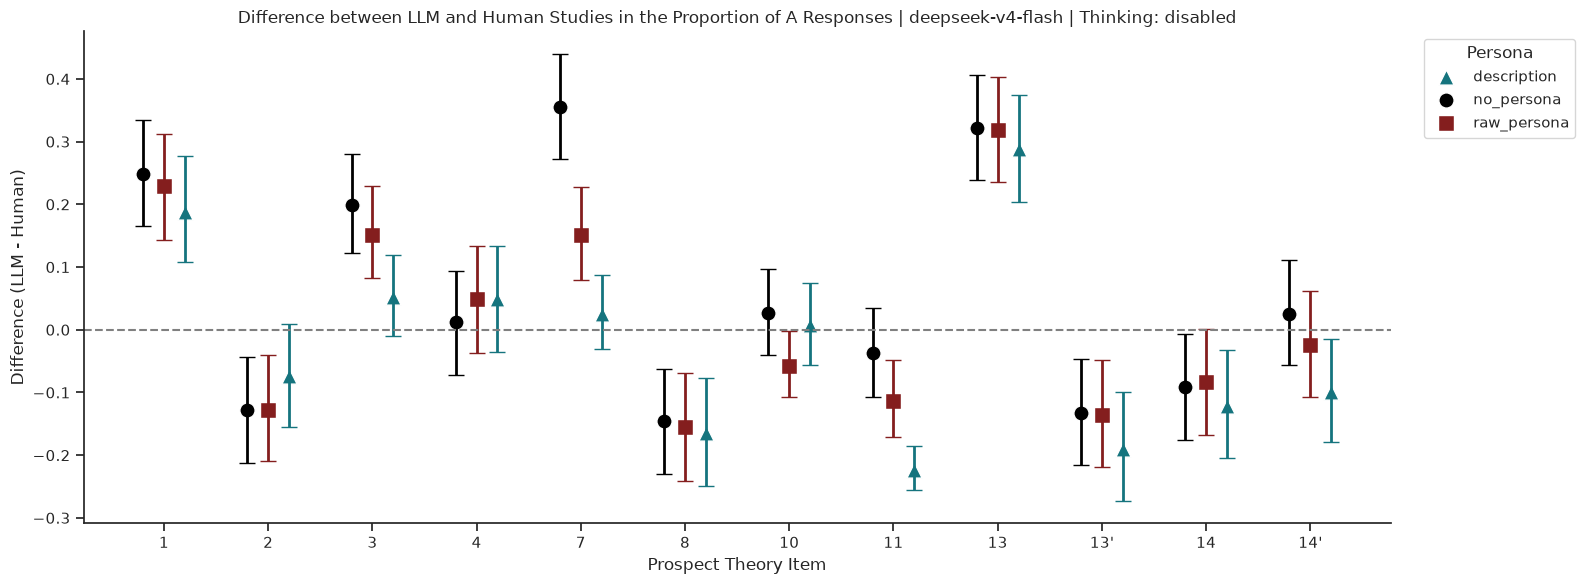

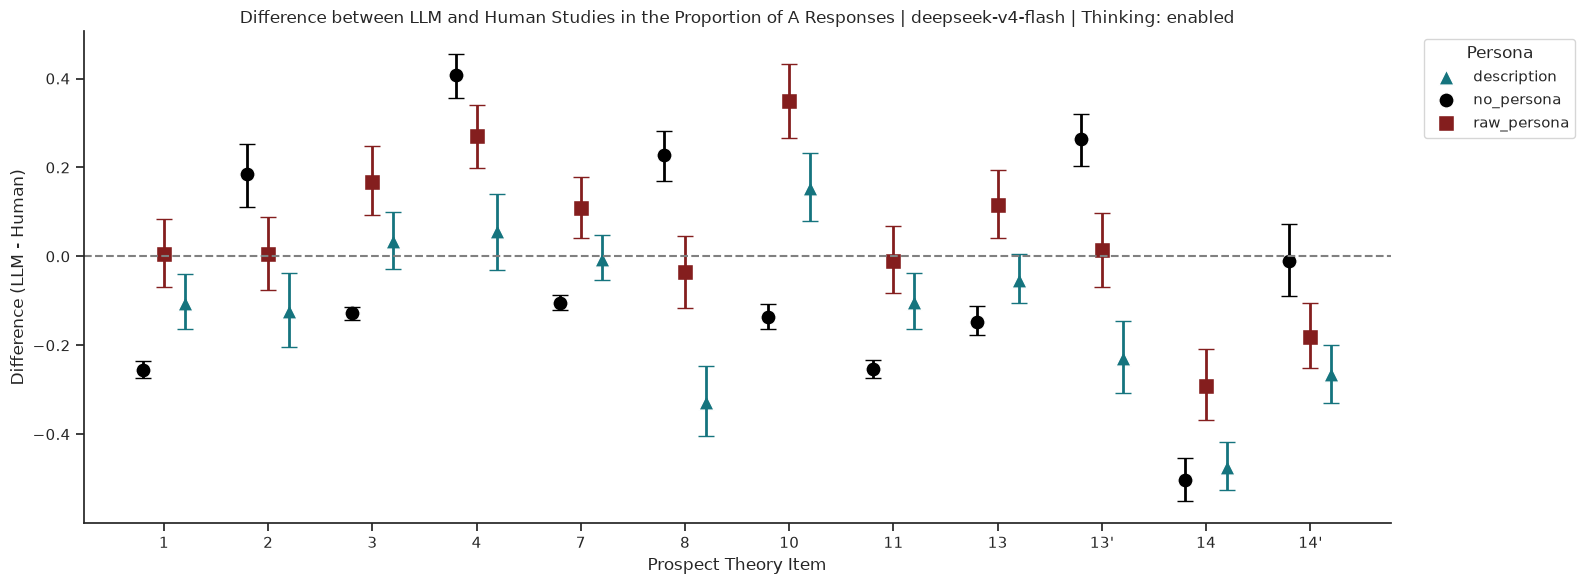

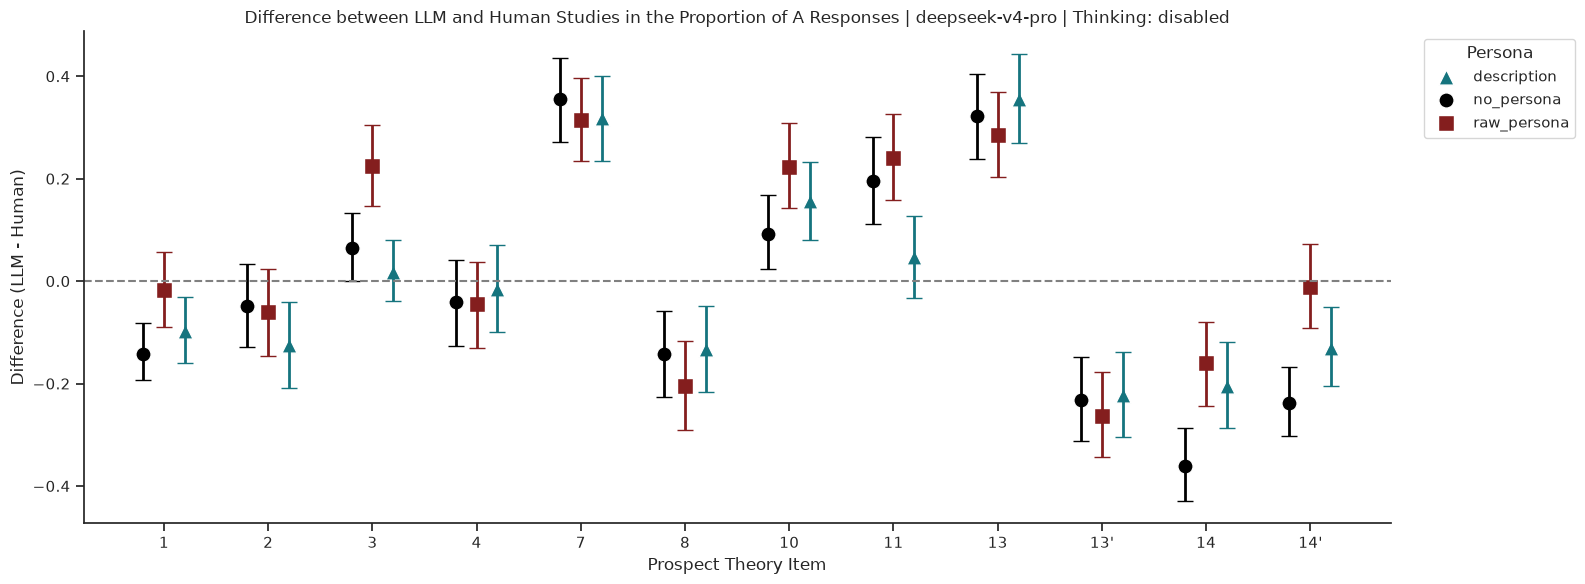

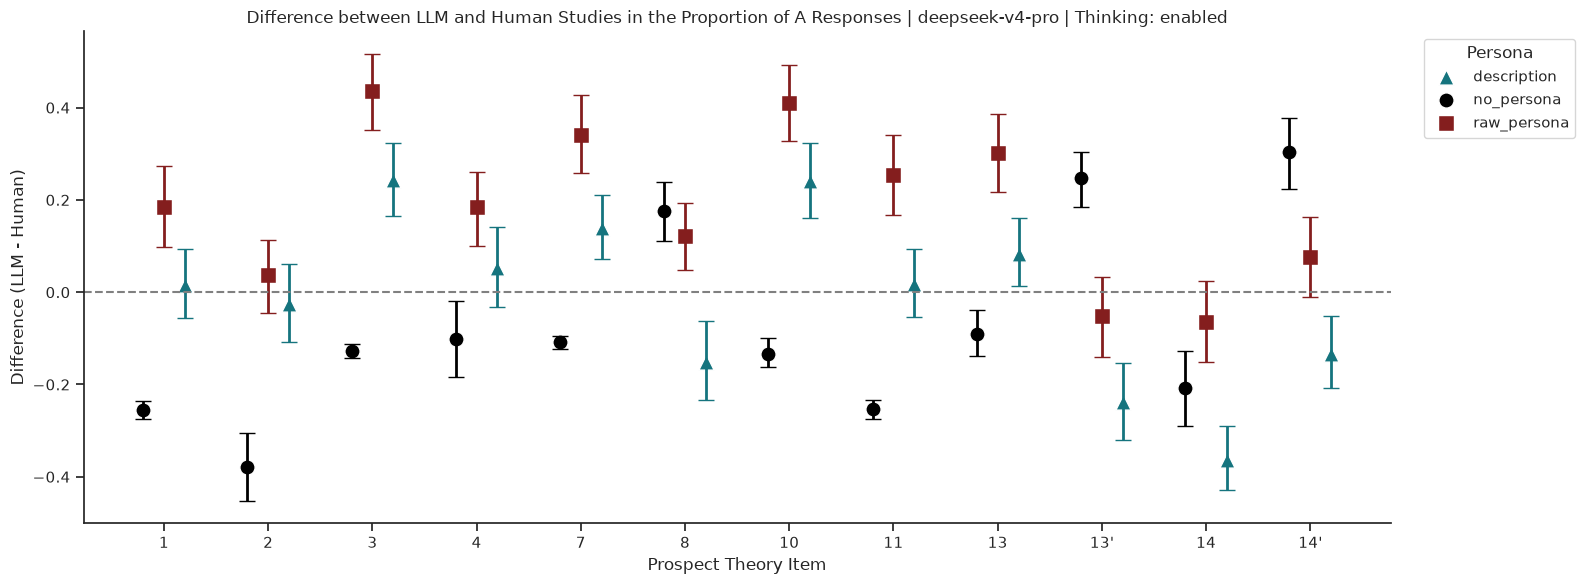

In [17]:
plot_item_level_results("delta_llm_human", "Difference (LLM - Human)", "Difference between LLM and Human Studies in the Proportion of A Responses")

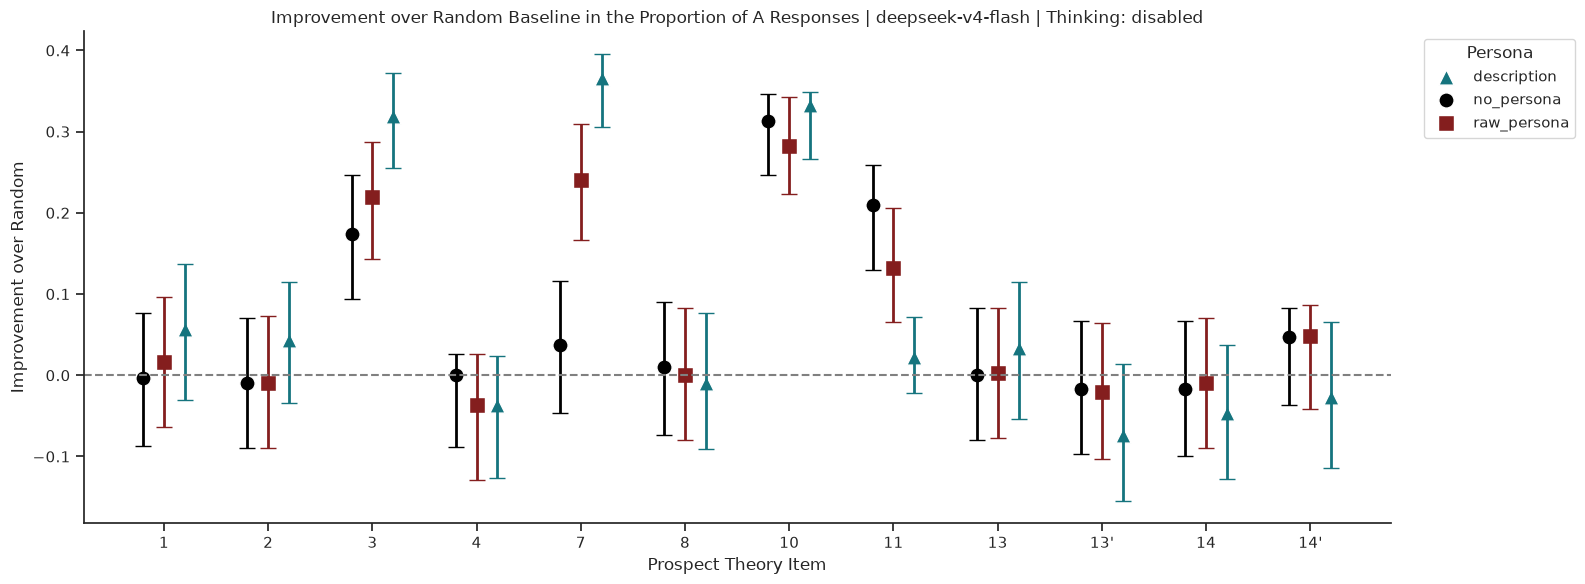

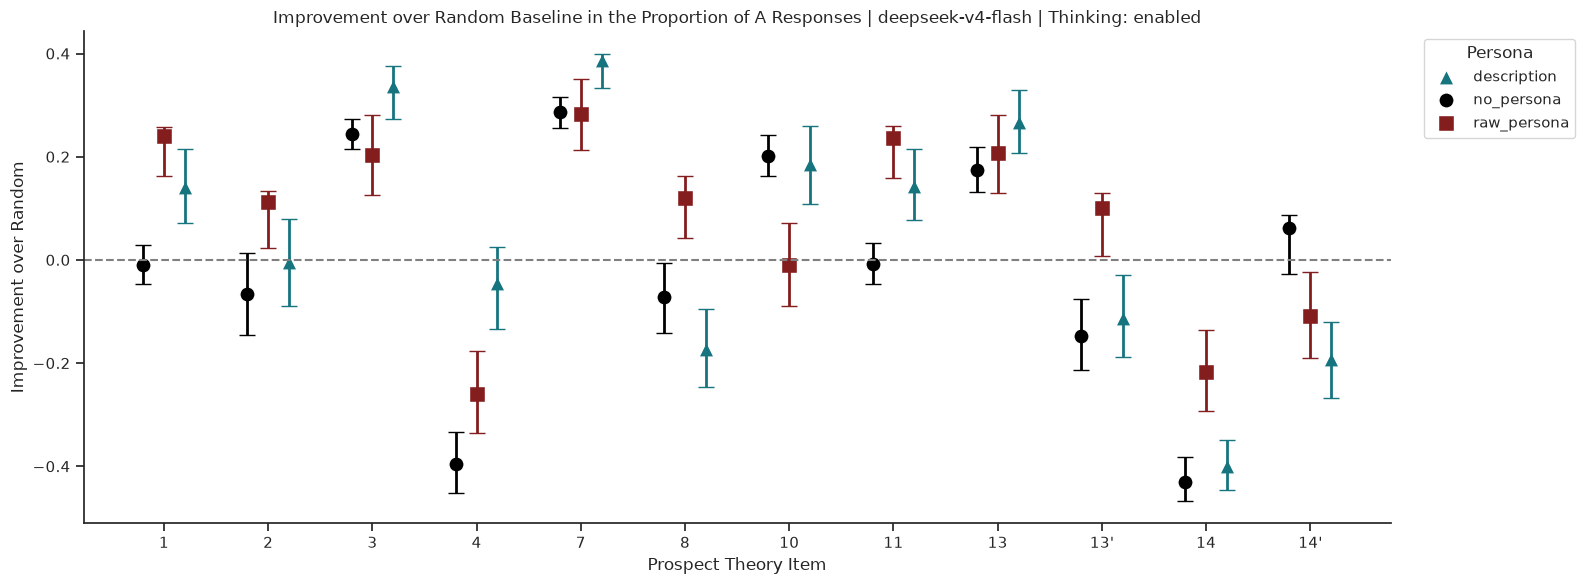

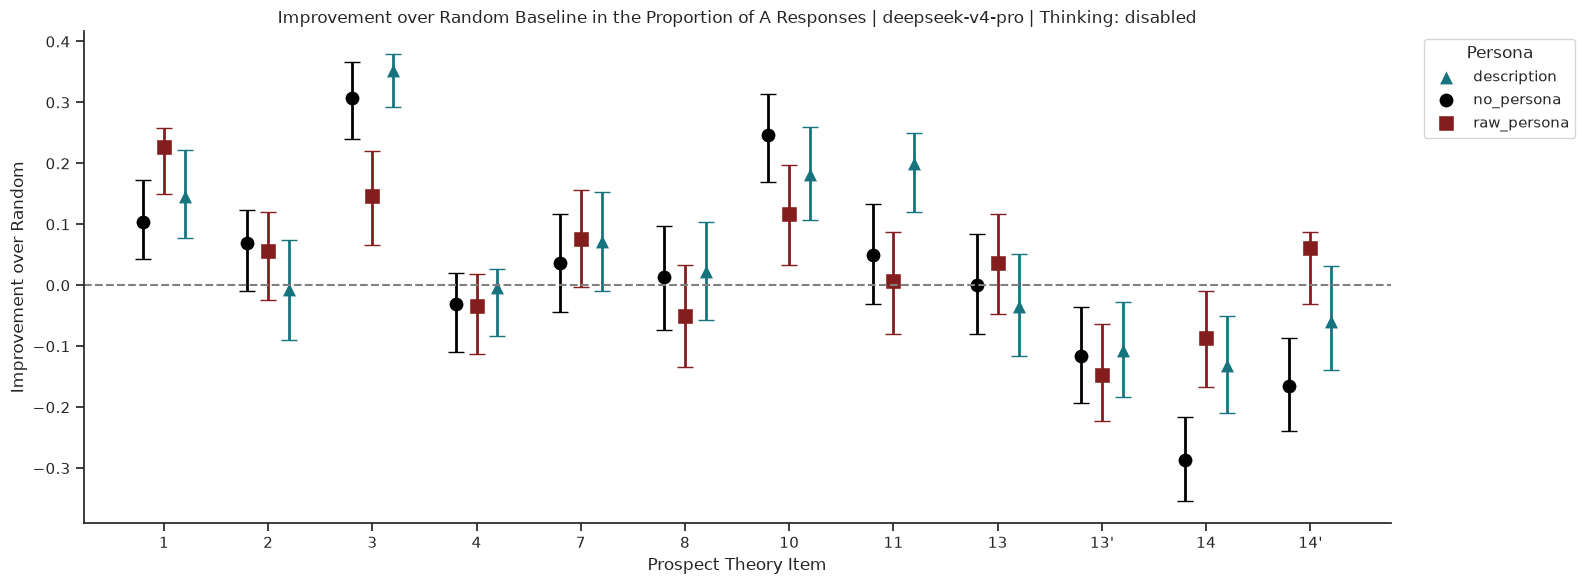

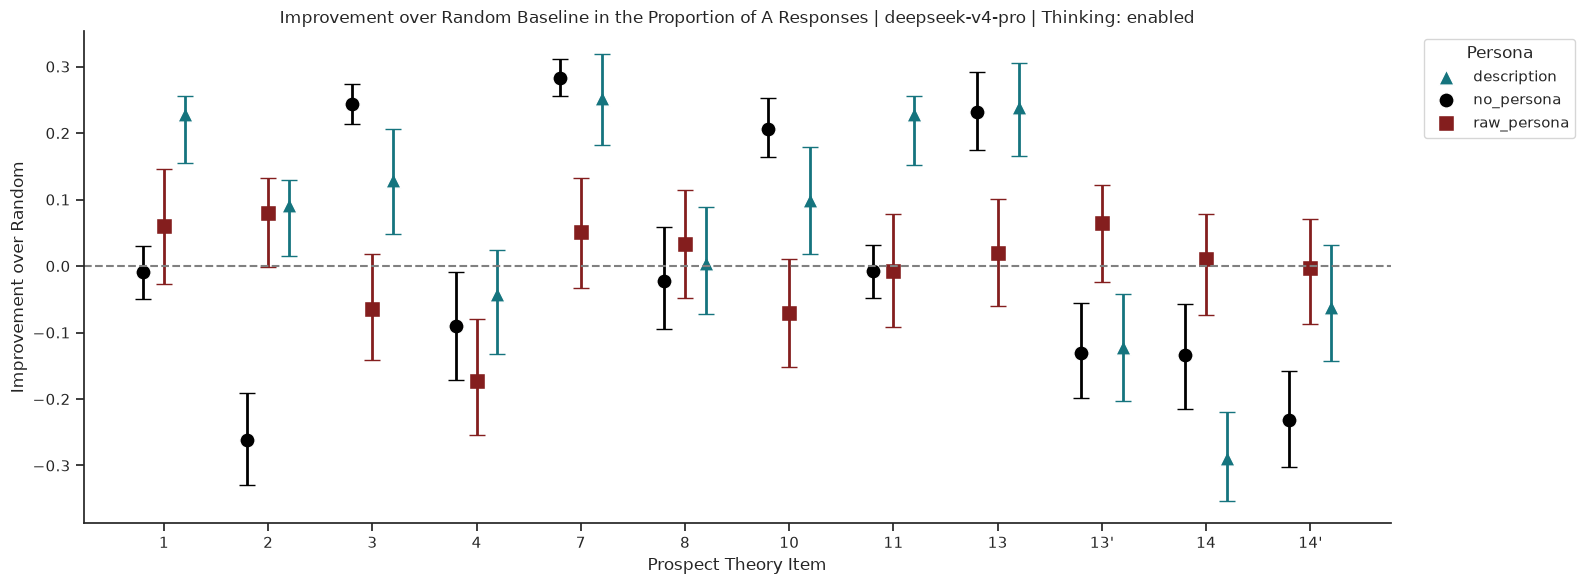

In [18]:
plot_item_level_results("improvement_over_random", "Improvement over Random", "Improvement over Random Baseline in the Proportion of A Responses")

In [19]:
def plot_aggregated_results(y_col_name, y_label, title):

    conditions = ["llm", "persona", "thinking"]
    if y_col_name == "delta_llm_human":
        bootstrap_summary["abs_error"] = bootstrap_summary["delta_llm_human"].abs()
        bootstrap_results["abs_error"] = bootstrap_results["delta_llm_human"].abs()
        y_col_name = "abs_error"
    
    # Mean improvement/MAE across all items for each condition
    agg_observed = (
        bootstrap_summary
        .groupby(conditions)[y_col_name]
        .mean()
        .reset_index(name="y_col")
    )

    # Same aggregate inside every bootstrap replicate
    agg_bootstrap = (
        bootstrap_results
        .groupby(conditions + ["bootstrap"])[y_col_name]
        .mean()
        .reset_index(name="y_col")
    )
    y_col_name = "MAE" if y_col_name == "abs_error" else y_col_name

    # Bonferroni adjustment for multiple comparisons
    if y_col_name == "improvement_over_random":
        n_tests = agg_observed.shape[0]
        alpha = 0.05 / n_tests
    else:
        alpha = 0.05 # MAE is only descriptive, no hypothesis testing

    if y_col_name == "MAE":
        agg_ci = (
            agg_bootstrap
            .groupby(conditions)["y_col"]
            .agg(
                MAE_lower_CI=lambda x: x.quantile(alpha / 2),
                MAE_upper_CI=lambda x: x.quantile(1 - alpha / 2)
            )
            .reset_index()
        )
    else:
        agg_ci = (
            agg_bootstrap
            .groupby(conditions)["y_col"]
            .agg(
                improvement_over_random_lower_CI=lambda x: x.quantile(alpha / 2),
                improvement_over_random_upper_CI=lambda x: x.quantile(1 - alpha / 2)
            )
            .reset_index()
        )

    df_summary = agg_observed.merge(agg_ci, on=conditions)

    sns.set_theme(font_scale=1, style="ticks")

    persona_order = ["no_persona", "raw_persona", "description"]
    persona_labels = {
        "no_persona": "No persona",
        "raw_persona": "Raw persona",
        "description": "Description"
    }
    persona_to_x = {p: i for i, p in enumerate(persona_order)}

    llm_colors = {"deepseek-v4-flash": "#000304", "deepseek-v4-pro": "#841E1E"}
    llm_labels = {"deepseek-v4-flash": "DeepSeek V4 Flash", "deepseek-v4-pro": "DeepSeek V4 Pro"}
    thinking_markers = {"disabled": "o", "enabled": "s"}
    thinking_labels = {"disabled": "Thinking disabled", "enabled": "Thinking enabled"}
    condition_offsets = {
        ("deepseek-v4-flash", "disabled"): -0.15,
        ("deepseek-v4-flash", "enabled"): -0.05,
        ("deepseek-v4-pro", "disabled"): 0.05,
        ("deepseek-v4-pro", "enabled"): 0.15,
    }

    plot_df = df_summary.copy()
    plot_df["x_pos"] = plot_df.apply(
        lambda r: persona_to_x[r["persona"]] + condition_offsets[(r["llm"], r["thinking"])], axis=1
    )

    fig, ax = plt.subplots(figsize=(10, 5))

    # Random baseline: improvement = 0
    if y_col_name == "improvement_over_random":
        ax.axhline(0, linestyle="--", color="grey", linewidth=1.5, zorder=0)

    for _, row in plot_df.iterrows():
        color = llm_colors[row["llm"]]
        ax.errorbar(
            row["x_pos"], row["y_col"],
            yerr=[[row["y_col"] - row[f"{y_col_name}_lower_CI"]], [row[f"{y_col_name}_upper_CI"] - row["y_col"]]],
            fmt="none", ecolor=color, elinewidth=1.5, capsize=5, zorder=2,
        )
        ax.scatter(
            row["x_pos"], row["y_col"],
            marker=thinking_markers[row["thinking"]], s=120,
            facecolor=color,
            edgecolor=color, linewidth=1.5, zorder=3,
        )

    ax.set_xticks(range(len(persona_order)))
    ax.set_xticklabels([persona_labels[p] for p in persona_order])
    ax.set_xlabel("Persona condition")
    ax.set_ylabel(f"{y_label}")
    ax.set_title(title)

    legend_handles = [
        Line2D([], [], color=llm_colors[k], linewidth=5, label=v) for k, v in llm_labels.items()
    ] + [
        Line2D([], [], linestyle="none", marker=thinking_markers[k], markersize=8, color="grey", label=v)
        for k, v in thinking_labels.items()
    ] 
    ax.legend(handles=legend_handles, title="Condition", bbox_to_anchor=(1.02, 1), loc="upper left")

    sns.despine()
    plt.tight_layout()
    plt.savefig(f"plots/risk_aversion_behavioral_alignment/{y_col_name}.png", bbox_inches="tight")
    df_summary = df_summary.rename(columns={"y_col": y_col_name})
    return df_summary

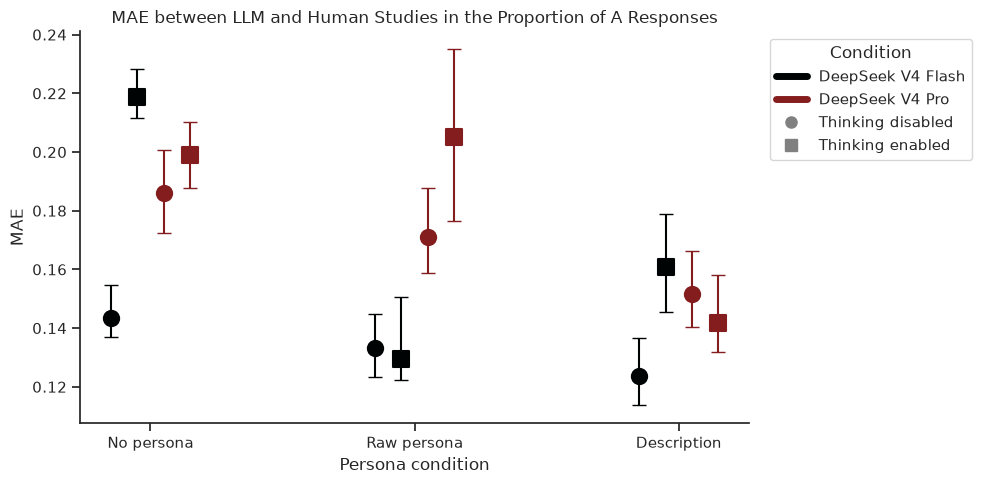

In [20]:
mae = plot_aggregated_results("delta_llm_human", "MAE", "MAE between LLM and Human Studies in the Proportion of A Responses")

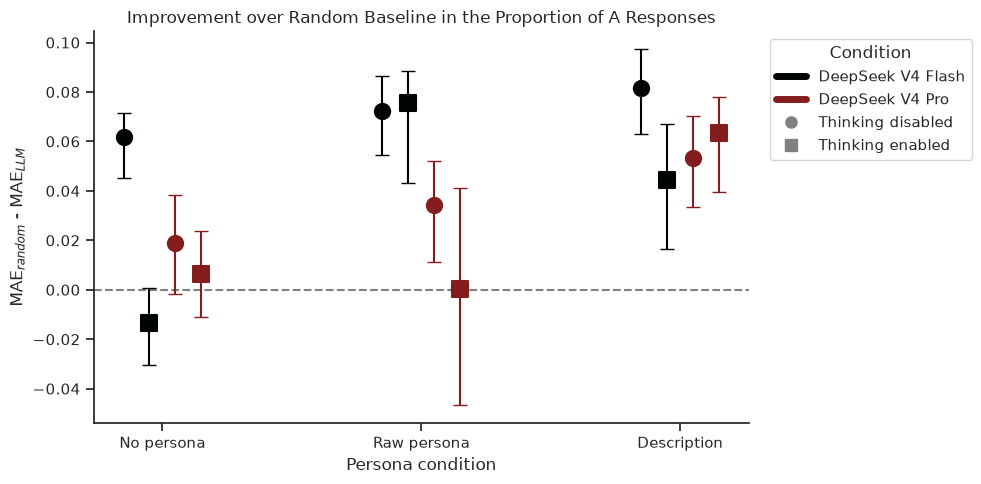

In [21]:
improvement = plot_aggregated_results(
    "improvement_over_random",
    "MAE$_{{random}}$ - MAE$_{{LLM}}$", 
    "Improvement over Random Baseline in the Proportion of A Responses"
    )

In [22]:
conditions = ["llm", "persona", "thinking"]

# Bootstrap CIs for the LLM and human proportion of A per item
direction_ci = (
    bootstrap_results
    .groupby(conditions + ["question"])
    .agg(
        llm_lower_CI=("A_p_llm", lambda x: x.quantile(alpha / 2)),
        llm_upper_CI=("A_p_llm", lambda x: x.quantile(1 - alpha / 2)),
        human_lower_CI=("A_p_human", lambda x: x.quantile(alpha / 2)),
        human_upper_CI=("A_p_human", lambda x: x.quantile(1 - alpha / 2)),
    )
    .reset_index()
)

# Which side of 0.5 is clearly preferred? (1 = A, -1 = B, 0 = no clear preference)
def preferred_side(lower, upper):
    if lower > 0.5:
        return 1
    if upper < 0.5:
        return -1
    return 0

direction_ci["llm_side"] = direction_ci.apply(lambda r: preferred_side(r["llm_lower_CI"], r["llm_upper_CI"]), axis=1)
direction_ci["human_side"] = direction_ci.apply(lambda r: preferred_side(r["human_lower_CI"], r["human_upper_CI"]), axis=1)

# Compare the LLM with the humans (1 = A, -1 = B, 0 = no clear preference)
def compare_direction(row):
    if row["llm_side"] == row["human_side"]:
        return "same"           # both A, both B, or both undecided
    if row["llm_side"] == 0 or row["human_side"] == 0:
        return "undecided_mismatch"  # either LLM or humans are undecided, but the other has a clear preference
    return "opposite_direction"  # LLM and humans have opposite preferences

direction_ci["direction"] = direction_ci.apply(compare_direction, axis=1)

# Count per condition + share of items with the same direction
direction_summary = (
    direction_ci
    .groupby(conditions)["direction"]
    .value_counts()
    .unstack(fill_value=0)
    .reset_index()
)
direction_summary["direction_consistency"] = (
    direction_summary["same"] / direction_ci.groupby(conditions).size().values
).round(2)
direction_summary

direction,llm,persona,thinking,opposite_direction,same,undecided_mismatch,direction_consistency
0,deepseek-v4-flash,description,disabled,0,6,6,0.50
1,deepseek-v4-flash,description,enabled,3,8,1,0.67
2,deepseek-v4-flash,no_persona,disabled,0,4,8,0.33
3,deepseek-v4-flash,no_persona,enabled,1,10,1,0.83
4,deepseek-v4-flash,raw_persona,disabled,0,6,6,0.50
5,deepseek-v4-flash,raw_persona,enabled,1,9,2,0.75
6,deepseek-v4-pro,description,disabled,2,6,4,0.50
7,deepseek-v4-pro,description,enabled,2,9,1,0.75
8,deepseek-v4-pro,no_persona,disabled,2,5,5,0.42
9,deepseek-v4-pro,no_persona,enabled,3,8,1,0.67


In [23]:
# Overall summary
analysis_summary = direction_summary.merge(position_bias_summary, on=["llm", "persona", "thinking"])
analysis_summary = analysis_summary.merge(improvement, on=["llm", "persona", "thinking"])
analysis_summary = analysis_summary.merge(mae, on=["llm", "persona", "thinking"])

analysis_summary.round(3)

,llm,persona,thinking,opposite_direction,same,undecided_mismatch,direction_consistency,position_bias,position_bias_p_A,position_bias_lower_CI,position_bias_upper_CI,position_bias_significant,improvement_over_random,improvement_over_random_lower_CI,improvement_over_random_upper_CI,MAE,MAE_lower_CI,MAE_upper_CI
0,deepseek-v4-flash,description,disabled,0,6,6,0.50,0.553,0.776,0.518,0.588,True,0.082,0.063,0.097,0.124,0.114,0.136
1,deepseek-v4-flash,description,enabled,3,8,1,0.67,-0.056,0.472,-0.153,0.035,False,0.045,0.016,0.067,0.161,0.146,0.179
2,deepseek-v4-flash,no_persona,disabled,0,4,8,0.33,0.775,0.888,0.753,0.798,True,0.062,0.045,0.071,0.143,0.137,0.155
3,deepseek-v4-flash,no_persona,enabled,1,10,1,0.83,0.001,0.500,-0.025,0.027,False,-0.014,-0.031,0.001,0.219,0.212,0.228
4,deepseek-v4-flash,raw_persona,disabled,0,6,6,0.50,0.720,0.860,0.694,0.746,True,0.072,0.055,0.086,0.133,0.123,0.145
5,deepseek-v4-flash,raw_persona,enabled,1,9,2,0.75,-0.037,0.482,-0.137,0.060,False,0.076,0.043,0.088,0.130,0.122,0.151
6,deepseek-v4-pro,description,disabled,2,6,4,0.50,-0.338,0.331,-0.386,-0.292,True,0.053,0.033,0.070,0.152,0.140,0.166
7,deepseek-v4-pro,description,enabled,2,9,1,0.75,-0.006,0.497,-0.125,0.110,False,0.063,0.039,0.078,0.142,0.132,0.158
8,deepseek-v4-pro,no_persona,disabled,2,5,5,0.42,-0.299,0.350,-0.338,-0.260,True,0.019,-0.002,0.038,0.186,0.173,0.201
9,deepseek-v4-pro,no_persona,enabled,3,8,1,0.67,0.066,0.533,0.036,0.096,True,0.006,-0.011,0.024,0.199,0.188,0.210


Bootstrap Contrasts:

In [34]:
# MAE per condition: point estimate and bootstrap replicates
mae_point = (bootstrap_summary
    .assign(abs_error=bootstrap_summary["delta_llm_human"].abs())
    .groupby(["llm", "persona", "thinking"])["abs_error"].mean())

mae_boot = (bootstrap_results
    .assign(abs_error=bootstrap_results["delta_llm_human"].abs())
    .groupby(["bootstrap", "llm", "persona", "thinking"])["abs_error"].mean()
    .unstack(["llm", "persona", "thinking"]))

def persona_effect(mae, llm, persona, thinking):
    """MAE(persona) - MAE(no persona); negative = persona closer to humans."""
    return mae[(llm, persona, thinking)] - mae[(llm, "no_persona", thinking)]

def thinking_effect(mae, llm, persona):
    """MAE(thinking on) - MAE(thinking off); negative = thinking closer to humans."""
    return mae[(llm, persona, "enabled")] - mae[(llm, persona, "disabled")]

def interaction(mae, llm, persona):
    """Persona effect with thinking on - persona effect with thinking off."""
    return (persona_effect(mae, llm, persona, "enabled") - persona_effect(mae, llm, persona, "disabled"))

# list of tests: (RQ, llm, comparison, held constant, function, its arguments)
tests = []
for llm in ["deepseek-v4-flash", "deepseek-v4-pro"]:
    for thinking in ["disabled", "enabled"]:
        for persona in ["raw_persona", "description"]:
            tests.append(("RQ2", llm, f"{persona} - no_persona", f"thinking {thinking}",
                          persona_effect, (llm, persona, thinking)))
    for persona in ["no_persona", "raw_persona", "description"]:
        tests.append(("RQ3", llm, "enabled - disabled", persona,
                      thinking_effect, (llm, persona)))
    for persona in ["raw_persona", "description"]:
        tests.append(("Interaction", llm, f"{persona} x thinking", "",
                      interaction, (llm, persona)))

alpha_contrast = 0.05 / len(tests)   # Bonferroni over all planned tests (18)

rows = []
for rq, llm, comparison, held_constant, effect_function, effect_args in tests:
    point_estimate = effect_function(mae_point, *effect_args)
    bootstrap_delta = effect_function(mae_boot, *effect_args)

    lower_bound, upper_bound = alpha_contrast / 2, 1 - alpha_contrast / 2
    lower_CI, upper_CI = bootstrap_delta.quantile([lower_bound, upper_bound])
    rows.append({
        "RQ": rq, 
        "llm": llm, 
        "comparison": comparison, 
        "held_constant": held_constant,
        "delta_MAE": point_estimate,
        "lower_CI": lower_CI, "upper_CI": upper_CI,
        "significant": lower_CI > 0 or upper_CI < 0,
    })

mae_contrasts = pd.DataFrame(rows)
print(f"{len(tests)} tests, {100 * (1 - alpha_contrast):.2f}% CIs")
mae_contrasts.round(3)

18 tests, 99.72% CIs


,RQ,llm,comparison,held_constant,delta_MAE,lower_CI,upper_CI,significant
0,RQ2,deepseek-v4-flash,raw_persona - no_persona,thinking disabled,-0.010,-0.033,0.009,False
1,RQ2,deepseek-v4-flash,description - no_persona,thinking disabled,-0.020,-0.043,0.003,False
2,RQ2,deepseek-v4-flash,raw_persona - no_persona,thinking enabled,-0.089,-0.108,-0.055,True
3,RQ2,deepseek-v4-flash,description - no_persona,thinking enabled,-0.058,-0.086,-0.028,True
4,RQ3,deepseek-v4-flash,enabled - disabled,no_persona,0.075,0.054,0.093,True
5,RQ3,deepseek-v4-flash,enabled - disabled,raw_persona,-0.003,-0.023,0.034,False
6,RQ3,deepseek-v4-flash,enabled - disabled,description,0.037,0.005,0.069,True
7,Interaction,deepseek-v4-flash,raw_persona x thinking,,-0.079,-0.105,-0.038,True
8,Interaction,deepseek-v4-flash,description x thinking,,-0.038,-0.075,0.000,False
9,RQ2,deepseek-v4-pro,raw_persona - no_persona,thinking disabled,-0.015,-0.043,0.018,False


# Correlations between Simulated Risk Aversion Answers and Assigned Personality Traits

Check if it makes sense to combine these items:

In [ ]:
df = pd.read_csv("../generated_data/loss_aversion_results_cleaned.csv")
cols = [c for c in df.columns if c.startswith("Loss_Aversion_")]

for col in cols:
    df.loc[~df[col].isin(["A", "B"]), col] = pd.NA

df = df.dropna(subset=cols).copy()

# Invert the responses for group 2
cols = [c for c in df.columns if c.startswith("Loss_Aversion_")]
mask = df["experiment_group"] == 2
swap = {"A": "B", "B": "A"}
df.loc[mask, cols] = df.loc[mask, cols].replace(swap)
print(f"Total missing values across df: {df.isna().sum().sum()}")

loss_cols = [
    "Loss_Aversion_1",
    "Loss_Aversion_3",
    "Loss_Aversion_5",
    "Loss_Aversion_7", 
    # "Loss_Aversion_9", # Removed as removing it increased Cronbach's alpha across the majority of conditions
    "Loss_Aversion_10",
    "Loss_Aversion_11",
    "Loss_Aversion_13",
    "Loss_Aversion_14", 
]

Total missing values across df: 0


**Across the thinking conditions with a persona removing any more items wouldn't meaningfully increase crohnbachs alpha any further**

In [ ]:
alpha_results = []

for (llm, persona, thinking), group in df.groupby(["llm", "persona", "thinking"]):

    items = group[loss_cols].replace({
        "A": 0,
        "B": 1
    }).astype(float)

    # Overall alpha
    overall_alpha = pg.cronbach_alpha(items)[0]

    result = {
        "llm": llm,
        "persona": persona,
        "thinking": thinking,
        "cronbach_alpha": overall_alpha
    }

    # Alpha if each item is removed
    for item in loss_cols:
        items_without = items.drop(columns=item)
        alpha_without = pg.cronbach_alpha(items_without)[0]

        result[f"alpha_without_{item}"] = alpha_without

    alpha_results.append(result)

alpha_df = pd.DataFrame(alpha_results)
alpha_df.round(2)

,llm,persona,thinking,cronbach_alpha,alpha_without_Loss_Aversion_1,alpha_without_Loss_Aversion_3,alpha_without_Loss_Aversion_5,alpha_without_Loss_Aversion_7,alpha_without_Loss_Aversion_10,alpha_without_Loss_Aversion_11,alpha_without_Loss_Aversion_13,alpha_without_Loss_Aversion_14
0,deepseek-v4-flash,description,disabled,0.79,0.71,0.78,0.71,0.78,0.84,0.79,0.73,0.71
1,deepseek-v4-flash,description,enabled,0.91,0.90,0.89,0.89,0.89,0.91,0.89,0.90,0.90
2,deepseek-v4-flash,no_persona,disabled,0.90,0.86,0.89,0.87,0.87,0.94,0.90,0.86,0.86
3,deepseek-v4-flash,no_persona,enabled,0.04,0.04,0.04,0.03,0.00,0.10,0.04,0.01,-0.00
4,deepseek-v4-flash,raw_persona,disabled,0.89,0.86,0.89,0.86,0.90,0.91,0.90,0.86,0.86
5,deepseek-v4-flash,raw_persona,enabled,0.88,0.86,0.86,0.86,0.87,0.86,0.87,0.85,0.86
6,deepseek-v4-pro,description,disabled,0.53,0.50,0.49,0.50,0.45,0.53,0.46,0.49,0.58
7,deepseek-v4-pro,description,enabled,0.93,0.92,0.93,0.93,0.92,0.93,0.92,0.93,0.93
8,deepseek-v4-pro,no_persona,disabled,0.49,0.48,0.41,0.44,0.41,0.50,0.40,0.50,0.51
9,deepseek-v4-pro,no_persona,enabled,-0.02,-0.02,-0.02,-0.00,-0.02,-0.02,-0.02,-0.07,0.10


In [ ]:
# check item intercorrelations within each condition
valid_condition = df[(df["thinking"] == "enabled") & ((df["persona"] != "no_persona"))].copy()

corr_matrices = []

for (llm, persona, thinking), condition in valid_condition.groupby(["llm", "persona", "thinking"]):

    items = condition[loss_cols].replace({
        "A": 0,
        "B": 1
    }).astype(float)
    
    corr = items.corr()
    corr.index = pd.MultiIndex.from_product(
        [[llm], [persona], [thinking], corr.index],
        names=["llm", "persona", "thinking", "item"]
    )
    
    corr_matrices.append(corr)

corr_df = pd.concat(corr_matrices)
corr_df.round(2)

Loss_Aversion_1  \
llm               persona     thinking item                                
deepseek-v4-flash description enabled  Loss_Aversion_1              1.00   
                                       Loss_Aversion_3              0.62   
                                       Loss_Aversion_5              0.55   
                                       Loss_Aversion_7              0.56   
                                       Loss_Aversion_10             0.56   
                                       Loss_Aversion_11             0.61   
                                       Loss_Aversion_13             0.50   
                                       Loss_Aversion_14             0.48   
                  raw_persona enabled  Loss_Aversion_1              1.00   
                                       Loss_Aversion_3              0.51   
                                       Loss_Aversion_5              0.49   
                                       Loss_Aversion_7              0.46   
                                       Loss_Aversion_10             0.54   
                                       Loss_Aversion_11             0.39   
                                       Loss_Aversion_13             0.60   
                                       Loss_Aversion_14             0.37   
deepseek-v4-pro   description enabled  Loss_Aversion_1              1.00   
                                       Loss_Aversion_3              0.65   
                                       Loss_Aversion_5              0.65   
                                       Loss_Aversion_7              0.73   
                                       Loss_Aversion_10             0.65   
                                       Loss_Aversion_11             0.75   
                                       Loss_Aversion_13             0.58   
                                       Loss_Aversion_14             0.59   
                  raw_persona enabled  Loss_Aversion_1              1.00   
                                       Loss_Aversion_3              0.69   
                                       Loss_Aversion_5              0.54   
                                       Loss_Aversion_7              0.63   
                                       Loss_Aversion_10             0.63   
                                       Loss_Aversion_11             0.65   
                                       Loss_Aversion_13             0.59   
                                       Loss_Aversion_14             0.62   

                                                         Loss_Aversion_3  \
llm               persona     thinking item                                
deepseek-v4-flash description enabled  Loss_Aversion_1              0.62   
                                       Loss_Aversion_3              1.00   
                                       Loss_Aversion_5              0.64   
                                       Loss_Aversion_7              0.62   
                                       Loss_Aversion_10             0.52   
                                       Loss_Aversion_11             0.67   
                                       Loss_Aversion_13             0.55   
                                       Loss_Aversion_14             0.57   
                  raw_persona enabled  Loss_Aversion_1              0.51   
                                       Loss_Aversion_3              1.00   
                                       Loss_Aversion_5              0.46   
                                       Loss_Aversion_7              0.44   
                                       Loss_Aversion_10             0.53   
                                       Loss_Aversion_11             0.41   
                                       Loss_Aversion_13             0.54   
                                       Loss_Aversion_14             0.43   
deepseek-v4-pro   description enabled  Loss_Aversion_1              0.65   
                            

In [ ]:
corr_df.min().min().round(2)    

np.float64(0.35)

In [ ]:
corr_df[corr_df != 1].max().max().round(2)

np.float64(0.8)

# Build the mean for B response (risk averse choice) and run correlations

In [ ]:
def get_subdomains():
    """Return Big Five subdomains."""
    
    big_five = {
        "Extraversion": ["Enthusiasm", "Assertiveness"],
        "Agreeableness": ["Compassion", "Politeness"],
        "Conscientiousness": ["Industriousness", "Orderliness"],
        "Neuroticism": ["Volatility", "Withdrawal"],
        "Openness_Intellect": ["Intellect", "Openness"],
    }

    return [subfacet for subfacets in big_five.values() for subfacet in subfacets]

subdomains = get_subdomains()

loss_binary = df[loss_cols].replace({
    "A": 0,
    "B": 1
}).astype(float)


# Calculate mean B proportion for each person
df_analysis = df[["llm", "persona", "thinking"] + subdomains].copy()
df_analysis["B_prop"] = loss_binary.mean(axis=1)

results = []
for (llm, persona, thinking), condition in df_analysis.groupby(["llm", "persona", "thinking"]):
    
    for trait in subdomains:

        x = condition[trait]
        y = condition["B_prop"]

        # Pearson
        res = pearsonr(x, y)
        alpha_adj = 0.05 / 120 # Bonferroni correction for multiple comparisons (10 traits * 12 conditions)
        ci = res.confidence_interval(confidence_level=1 - alpha_adj, method=BootstrapMethod(n_resamples=10_000, random_state=42))  # 99.96% CI 
        r, lower, upper = res.statistic, ci.low, ci.high
        p_pearson = res.pvalue 
        
        # Spearman
        r_spearman, p_spearman = spearmanr(x, y)

        results.append({
            "llm": llm,
            "persona": persona,
            "thinking": thinking,
            "trait": trait,
            "pearson_r": r,
            "pearson_p": p_pearson,
            "pearson_lower_CI": lower,
            "pearson_upper_CI": upper,
            "spearman_rho": r_spearman,
            "spearman_p": p_spearman,
            "N": len(condition)
        })


correlation_df = pd.DataFrame(results)
correlation_df["pearson_p_bonferroni"] = (correlation_df["pearson_p"] * len(correlation_df)).clip(upper=1.0)
correlation_df["spearman_p_bonferroni"] = (correlation_df["spearman_p"] * len(correlation_df)).clip(upper=1.0)
correlation_df.round(2)

,llm,persona,thinking,trait,pearson_r,pearson_p,pearson_lower_CI,pearson_upper_CI,spearman_rho,spearman_p,N,pearson_p_bonferroni,spearman_p_bonferroni
0,deepseek-v4-flash,description,disabled,Enthusiasm,-0.01,0.87,-0.21,0.19,-0.03,0.65,298,1.0,1.0
1,deepseek-v4-flash,description,disabled,Assertiveness,-0.07,0.21,-0.28,0.14,-0.08,0.18,298,1.0,1.0
2,deepseek-v4-flash,description,disabled,Compassion,-0.00,0.93,-0.19,0.21,-0.02,0.68,298,1.0,1.0
3,deepseek-v4-flash,description,disabled,Politeness,0.09,0.12,-0.13,0.31,0.07,0.24,298,1.0,1.0
4,deepseek-v4-flash,description,disabled,Industriousness,0.01,0.88,-0.19,0.22,0.01,0.84,298,1.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
115,deepseek-v4-pro,raw_persona,enabled,Orderliness,0.29,0.00,0.10,0.45,0.28,0.00,293,0.0,0.0
116,deepseek-v4-pro,raw_persona,enabled,Volatility,0.36,0.00,0.17,0.52,0.37,0.00,293,0.0,0.0
117,deepseek-v4-pro,raw_persona,enabled,Withdrawal,0.70,0.00,0.57,0.77,0.72,0.00,293,0.0,0.0
118,deepseek-v4-pro,raw_persona,enabled,Intellect,-0.49,0.00,-0.62,-0.34,-0.49,0.00,293,0.0,0.0


In [ ]:
correlation_valid = correlation_df[(correlation_df["persona"] != "no_persona") & (correlation_df["thinking"] == "enabled")]
correlation_valid

,llm,persona,thinking,trait,pearson_r,pearson_p,pearson_lower_CI,pearson_upper_CI,spearman_rho,spearman_p,N,pearson_p_bonferroni,spearman_p_bonferroni
10,deepseek-v4-flash,description,enabled,Enthusiasm,-0.319374,1.623667e-08,-0.495881,-0.086351,-0.313846,2.941354e-08,299,1.948401e-06,3.529625e-06
11,deepseek-v4-flash,description,enabled,Assertiveness,-0.488144,2.620166e-19,-0.617018,-0.331074,-0.544739,1.668309e-24,299,3.144199e-17,2.001971e-22
12,deepseek-v4-flash,description,enabled,Compassion,0.106645,6.553389e-02,-0.107754,0.321186,0.098830,8.801651e-02,299,1.000000e+00,1.000000e+00
13,deepseek-v4-flash,description,enabled,Politeness,0.434024,3.637371e-15,0.236036,0.596254,0.364603,7.852913e-11,299,4.364845e-13,9.423496e-09
14,deepseek-v4-flash,description,enabled,Industriousness,-0.039329,4.981012e-01,-0.209002,0.156948,-0.133966,2.049035e-02,299,1.000000e+00,1.000000e+00
15,deepseek-v4-flash,description,enabled,Orderliness,0.379243,1.157621e-11,0.192113,0.562015,0.336257,2.451740e-09,299,1.389146e-09,2.942088e-07
16,deepseek-v4-flash,description,enabled,Volatility,-0.110188,5.702212e-02,-0.317473,0.116481,-0.005199,9.286636e-01,299,1.000000e+00,1.000000e+00
17,deepseek-v4-flash,description,enabled,Withdrawal,0.289917,3.358436e-07,0.155723,0.438751,0.430873,6.025792e-15,299,4.030123e-05,7.230950e-13
18,deepseek-v4-flash,description,enabled,Intellect,-0.327353,6.741072e-09,-0.476847,-0.189900,-0.431038,5.868954e-15,299,8.089287e-07,7.042745e-13
19,deepseek-v4-flash,description,enabled,Openness,-0.104150,7.213313e-02,-0.281337,0.112563,-0.130976,2.350892e-02,299,1.000000e+00,1.000000e+00


# use the full personality profile (all subdomains) to try to predict the mean B response (risk averse outcome)

In [ ]:
subdomains = get_subdomains()
df_analysis = df[["llm", "persona", "thinking"] + subdomains].copy()
df_analysis["B_prop"] = loss_binary.mean(axis=1)

cv = RepeatedKFold(n_splits=5, n_repeats=10, random_state=1)
scoring = {"r2": "r2", "mae": "neg_mean_absolute_error"}
rows = []
for (llm, persona, thinking), cond in df_analysis.groupby(["llm", "persona", "thinking"]):

    X = cond[subdomains]
    y = cond["B_prop"]

    ols = make_pipeline(StandardScaler(), LinearRegression())
    xgb = XGBRegressor(
            n_estimators=200,
            max_depth=2, 
            learning_rate=0.05,
            subsample=0.8, 
            random_state=1,
            n_jobs=1
            )

    res_ols = cross_validate(ols, X, y, cv=cv, scoring=scoring)
    res_xgb = cross_validate(xgb, X, y, cv=cv, scoring=scoring)

    rows.append({
        "llm": llm, "persona": persona, "thinking": thinking,
        "cv_r2_ols": res_ols["test_r2"].mean(),
        "cv_mae_ols": -res_ols["test_mae"].mean(),
        "cv_r2_xgb": res_xgb["test_r2"].mean(),
        "cv_mae_xgb": -res_xgb["test_mae"].mean(),
        "mae_baseline": (y - y.mean()).abs().mean(), # reference: MAE when always predicting the mean
    })

cv_results = pd.DataFrame(rows).round(3)

In [ ]:
cv_results

,llm,persona,thinking,cv_r2_ols,cv_mae_ols,cv_r2_xgb,cv_mae_xgb,mae_baseline
0,deepseek-v4-flash,description,disabled,-0.080,0.252,-0.242,0.260,0.244
1,deepseek-v4-flash,description,enabled,0.501,0.154,0.595,0.118,0.215
2,deepseek-v4-flash,no_persona,disabled,-0.078,0.353,-0.176,0.356,0.346
3,deepseek-v4-flash,no_persona,enabled,-0.084,0.037,-0.209,0.037,0.036
4,deepseek-v4-flash,raw_persona,disabled,-0.074,0.330,-0.220,0.340,0.324
5,deepseek-v4-flash,raw_persona,enabled,0.718,0.141,0.780,0.115,0.294
6,deepseek-v4-pro,description,disabled,0.179,0.155,0.128,0.157,0.178
7,deepseek-v4-pro,description,enabled,0.627,0.185,0.676,0.159,0.329
8,deepseek-v4-pro,no_persona,disabled,-0.063,0.179,-0.144,0.184,0.176
9,deepseek-v4-pro,no_persona,enabled,-0.046,0.069,-0.169,0.070,0.070
